# 🏡 Real Estate Investment Advisor: Predicting Property Profitability & Future Value

**Developed by:** Bhagyashri Patil

## Problem Statement

Real estate investment decisions involve several factors, including property prices, location, size, amenities, and surrounding infrastructure. Evaluating these factors manually can be time-consuming and may lead to decisions based on incomplete information.

The objective of this project is to develop a machine learning-based Real Estate Investment Advisor that helps potential investors assess property investment potential and estimate future property values using data-driven analysis.

## Objectives

- Analyze and preprocess the Indian housing prices dataset.
- Perform Exploratory Data Analysis (EDA) to identify patterns and relationships in property prices.
- Apply feature engineering to create meaningful features for investment analysis.
- Develop a classification model to predict whether a property is a good investment.
- Build a regression model to estimate property prices after five years using a clearly defined forecasting methodology.
- Evaluate and compare machine learning models using appropriate performance metrics.
- Use MLflow to track experiments and manage model performance.
- Save trained models for future predictions.
- Develop an interactive Streamlit application to display investment predictions and property insights.

## 1. Import Required Libraries

In this section, we import the Python libraries required for data manipulation, visualization, preprocessing, machine learning, model evaluation, experiment tracking, and model saving.

These libraries will support the complete machine learning workflow, from data analysis to model development and deployment.

In [1]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing and machine learning pipelines
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Classification models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Regression models
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model saving and file management
import joblib
import os

# Experiment tracking
import mlflow
import mlflow.sklearn

# Suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Configure Pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Set visualization style
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully!")

C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\pydantic\_internal\_fields.py:132: UserWarning: Field "model_name" in PromptModelConfig has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(


All required libraries imported successfully!


## 2. Load the Dataset

In this section, we load the Indian housing prices dataset into a Pandas DataFrame. The dataset contains information about properties, including their location, property type, size, price, furnishing status, amenities, and nearby facilities.

Loading the dataset is the first step toward understanding the data and preparing it for further analysis and machine learning.

In [2]:
# Define the dataset file path
DATA_PATH = "india_housing_prices.csv"

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(DATA_PATH)

# Display a success message
print("Dataset loaded successfully!")

# Display the number of rows and columns
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

# Display the first five records
display(df.head())

Dataset loaded successfully!
Number of rows: 250000
Number of columns: 23


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## 3. Initial Data Inspection

In this section, we examine the structure and basic characteristics of the housing dataset. We inspect column names, data types, non-null values, and statistical summaries to understand the information available for analysis.

This step helps identify numerical and categorical features and highlights potential data quality issues that may need to be addressed during preprocessing.

In [3]:
# Display all column names
print("Column Names:")
print(df.columns.tolist())

# Display dataset structure, data types, and non-null counts
print("\nDataset Information:")
df.info()

# Display the number of rows and columns
print("\nDataset Shape:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# Display the first five records
print("\nFirst Five Records:")
display(df.head())

# Display statistical summary of numerical columns
print("\nNumerical Features Summary:")
display(df.describe().T)

# Display summary of both numerical and categorical columns
print("\nComplete Dataset Summary:")
display(df.describe(include="all").T)

Column Names:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6 

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move



Numerical Features Summary:


,count,mean,std,min,25%,50%,75%,max
ID,"250,000.00","125,000.50","72,168.93",1.00,"62,500.75","125,000.50","187,500.25","250,000.00"
BHK,"250,000.00",3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00","2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,"250,000.00",0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,"250,000.00","2,006.52",9.81,"1,990.00","1,998.00","2,007.00","2,015.00","2,023.00"
Floor_No,"250,000.00",14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,"250,000.00",15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,"250,000.00",18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,"250,000.00",5.50,2.88,1.00,3.00,5.00,8.00,10.00



Complete Dataset Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,"250,000.00",NaN,NaN,NaN,"125,000.50","72,168.93",1.00,"62,500.75","125,000.50","187,500.25","250,000.00"
State,250000,20,Odisha,12681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,250000,42,Coimbatore,6461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality,250000,500,Locality_296,567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Property_Type,250000,3,Villa,83744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BHK,"250,000.00",NaN,NaN,NaN,3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00",NaN,NaN,NaN,"2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",NaN,NaN,NaN,254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,"250,000.00",NaN,NaN,NaN,0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,"250,000.00",NaN,NaN,NaN,"2,006.52",9.81,"1,990.00","1,998.00","2,007.00","2,015.00","2,023.00"


## 4. Checking Missing Values and Duplicate Records

Data quality is an important part of machine learning. Missing values can affect model training, while duplicate records can introduce bias and lead to misleading results.

In this section, we identify missing values in each column and check for duplicate rows. We will use these results to decide the appropriate data-cleaning strategy in the next steps.

In [4]:
# ============================================================
# 4. CHECKING MISSING VALUES AND DUPLICATE RECORDS
# ============================================================

# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values in each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine missing-value counts and percentages into a DataFrame
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Display only columns containing missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

print("Missing Values Summary:")
if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary.sort_values(
        by="Missing Percentage", ascending=False
    ))

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print(f"\nNumber of duplicate rows: {duplicate_count}")

# Display the percentage of duplicate rows
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Percentage of duplicate rows: {duplicate_percentage:.2f}%")

Missing Values Summary:
No missing values found.

Number of duplicate rows: 0
Percentage of duplicate rows: 0.00%


## 5. Data Cleaning

Data cleaning is an important step in preparing a dataset for analysis and machine learning. It helps improve data consistency and ensures that the data is suitable for further processing.

After checking the dataset, we found **no missing values and no duplicate records**. Therefore, no missing-value imputation or duplicate removal is required at this stage.

We will standardize the column names for easier coding and readability. We will also inspect the dataset for incorrect data types, inconsistent categorical values, and invalid records during subsequent preprocessing.

Since the dataset is already complete and contains no duplicate rows, we will preserve the available records and avoid unnecessary data removal.

In [5]:
# ============================================================
# 5. DATA CLEANING
# ============================================================

# Standardize column names by removing extra spaces
# and replacing spaces with underscores
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

# Verify missing values
print("Total missing values:", df.isnull().sum().sum())

# Verify duplicate records
print("Total duplicate records:", df.duplicated().sum())

# Display standardized column names
print("\nStandardized Column Names:")
print(df.columns.tolist())

# Display the cleaned dataset
print("\nDataset after basic cleaning:")
display(df.head())

Total missing values: 0
Total duplicate records: 0

Standardized Column Names:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Dataset after basic cleaning:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is used to understand the distribution, characteristics, and relationships within the housing dataset. It helps identify important patterns that may influence property prices and investment potential.

In this section, we will investigate property prices, property sizes, property types, locations, and relationships between numerical and categorical features using statistical summaries and visualizations.

The findings from EDA will guide feature selection and help us understand which factors may be useful for the classification and regression models.

In [86]:
# ============================================================
# IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Display numerical features
print("Numerical Features:")
print(numerical_columns)

# Display categorical features
print("\nCategorical Features:")
print(categorical_columns)

# Display feature counts
print(f"\nNumber of numerical features: {len(numerical_columns)}")
print(f"Number of categorical features: {len(categorical_columns)}")

Numerical Features:
['ID', 'Price_in_Lakhs', 'Crime_Rate_Index', 'Infrastructure_Score']

Categorical Features:
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Number of numerical features: 4
Number of categorical features: 11


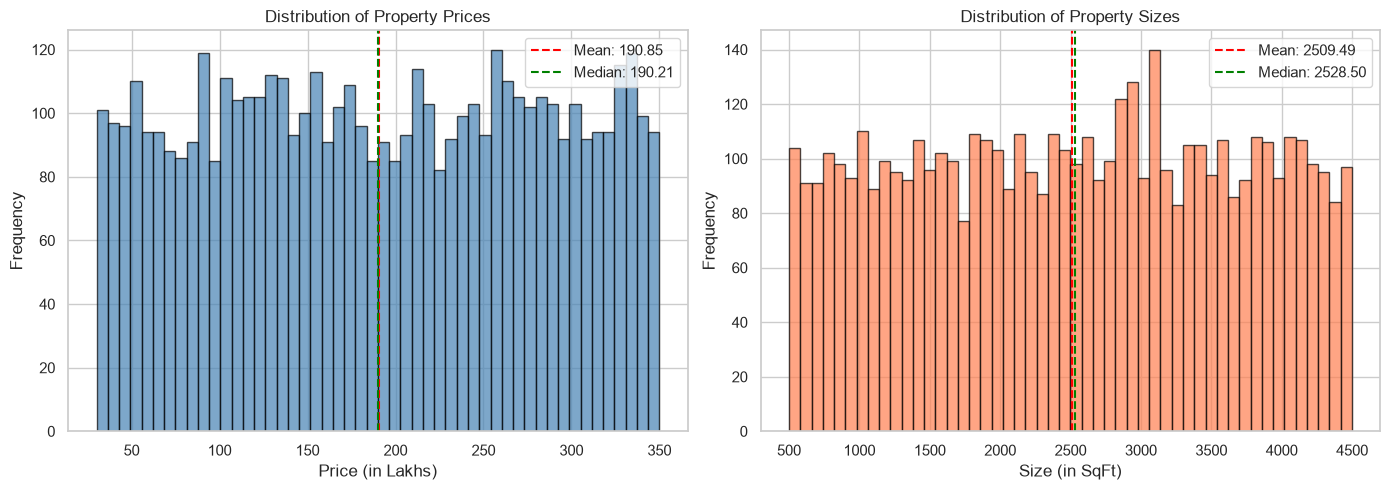

Key Statistics:
Price - Mean: 190.85, Median: 190.21, Std: 92.42
Size - Mean: 2509.49, Median: 2528.50, Std: 1143.07


In [97]:
# Q1: Distribution of property prices
# Q2: Distribution of property sizes

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price distribution
axes[0].hist(df['Price_in_Lakhs'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Price (in Lakhs)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Property Prices')
axes[0].axvline(df['Price_in_Lakhs'].mean(), color='red', linestyle='--', label=f'Mean: {df["Price_in_Lakhs"].mean():.2f}')
axes[0].axvline(df['Price_in_Lakhs'].median(), color='green', linestyle='--', label=f'Median: {df["Price_in_Lakhs"].median():.2f}')
axes[0].legend()

# Size distribution
axes[1].hist(df['Size_in_SqFt'], bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Size (in SqFt)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Property Sizes')
axes[1].axvline(df['Size_in_SqFt'].mean(), color='red', linestyle='--', label=f'Mean: {df["Size_in_SqFt"].mean():.2f}')
axes[1].axvline(df['Size_in_SqFt'].median(), color='green', linestyle='--', label=f'Median: {df["Size_in_SqFt"].median():.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Key Statistics:")
print(f"Price - Mean: {df['Price_in_Lakhs'].mean():.2f}, Median: {df['Price_in_Lakhs'].median():.2f}, Std: {df['Price_in_Lakhs'].std():.2f}")
print(f"Size - Mean: {df['Size_in_SqFt'].mean():.2f}, Median: {df['Size_in_SqFt'].median():.2f}, Std: {df['Size_in_SqFt'].std():.2f}")

In [103]:
print(df.columns.tolist())

['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status', 'Crime_Rate_Index', 'Infrastructure_Score']


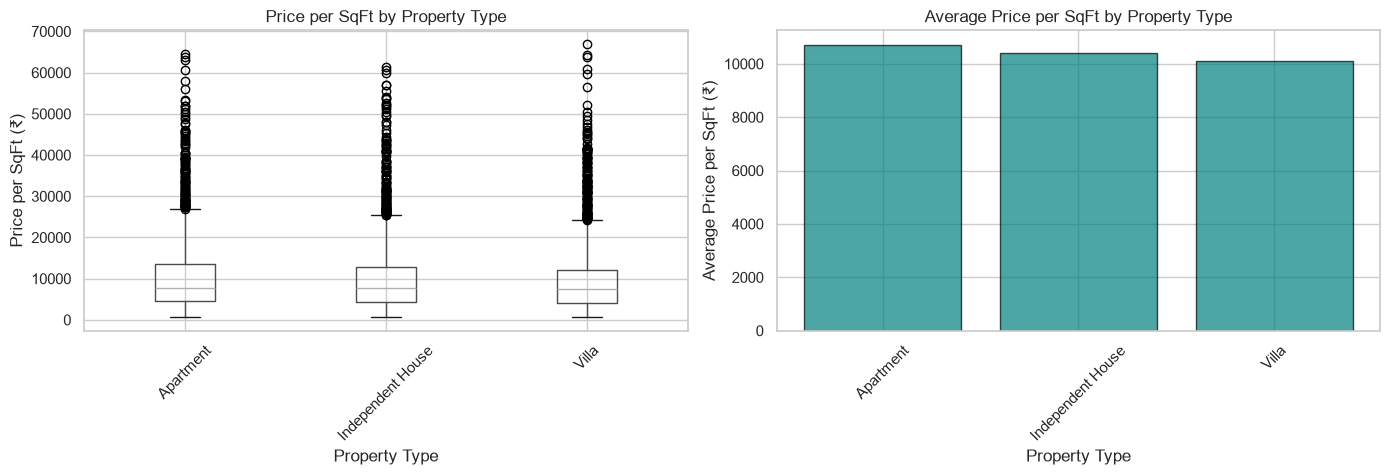

Price per SqFt by Property Type:
                       mean   median      std    min       max
Property_Type                                                 
Apartment         10,714.17 7,774.13 9,478.67 686.87 64,490.42
Independent House 10,417.45 7,662.55 9,361.00 753.13 61,356.95
Villa             10,105.00 7,460.19 9,314.93 753.46 66,917.60


In [104]:
# Q3: How does price per sqft vary by property type?

# Calculate price per square foot
df["Price_per_SqFt"] = (df["Price_in_Lakhs"] * 100000) / df["Size_in_SqFt"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot
df.boxplot(column="Price_per_SqFt", by="Property_Type", ax=axes[0])
axes[0].set_xlabel("Property Type")
axes[0].set_ylabel("Price per SqFt (₹)")
axes[0].set_title("Price per SqFt by Property Type")
axes[0].tick_params(axis="x", rotation=45)

# Bar plot with mean values
price_by_type = (
    df.groupby("Property_Type")["Price_per_SqFt"]
    .mean()
    .sort_values(ascending=False)
)

axes[1].bar(
    price_by_type.index,
    price_by_type.values,
    color="teal",
    edgecolor="black",
    alpha=0.7
)
axes[1].set_xlabel("Property Type")
axes[1].set_ylabel("Average Price per SqFt (₹)")
axes[1].set_title("Average Price per SqFt by Property Type")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("")
plt.tight_layout()
plt.show()

print("Price per SqFt by Property Type:")
print(
    df.groupby("Property_Type")["Price_per_SqFt"]
    .agg(["mean", "median", "std", "min", "max"])
)

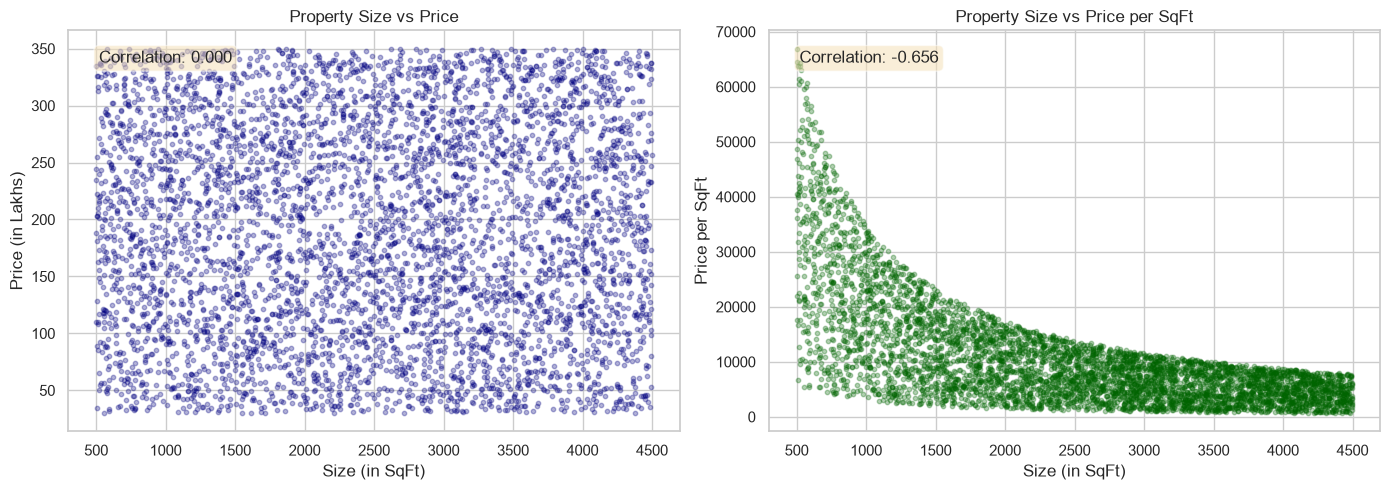

Correlation between Size and Price: 0.0001
Correlation between Size and Price_per_SqFt: -0.6558


In [105]:
# Q4: Is there a relationship between property size and price?

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(df['Size_in_SqFt'], df['Price_in_Lakhs'], alpha=0.3, s=10, color='navy')
axes[0].set_xlabel('Size (in SqFt)')
axes[0].set_ylabel('Price (in Lakhs)')
axes[0].set_title('Property Size vs Price')

# Calculate correlation
correlation = df['Size_in_SqFt'].corr(df['Price_in_Lakhs'])
axes[0].text(0.05, 0.95, f'Correlation: {correlation:.3f}',
             transform=axes[0].transAxes, fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Price per sqft scatter
axes[1].scatter(df['Size_in_SqFt'], df['Price_per_SqFt'], alpha=0.3, s=10, color='darkgreen')
axes[1].set_xlabel('Size (in SqFt)')
axes[1].set_ylabel('Price per SqFt')
axes[1].set_title('Property Size vs Price per SqFt')

correlation2 = df['Size_in_SqFt'].corr(df['Price_per_SqFt'])
axes[1].text(0.05, 0.95, f'Correlation: {correlation2:.3f}',
             transform=axes[1].transAxes, fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print(f"Correlation between Size and Price: {correlation:.4f}")
print(f"Correlation between Size and Price_per_SqFt: {correlation2:.4f}")

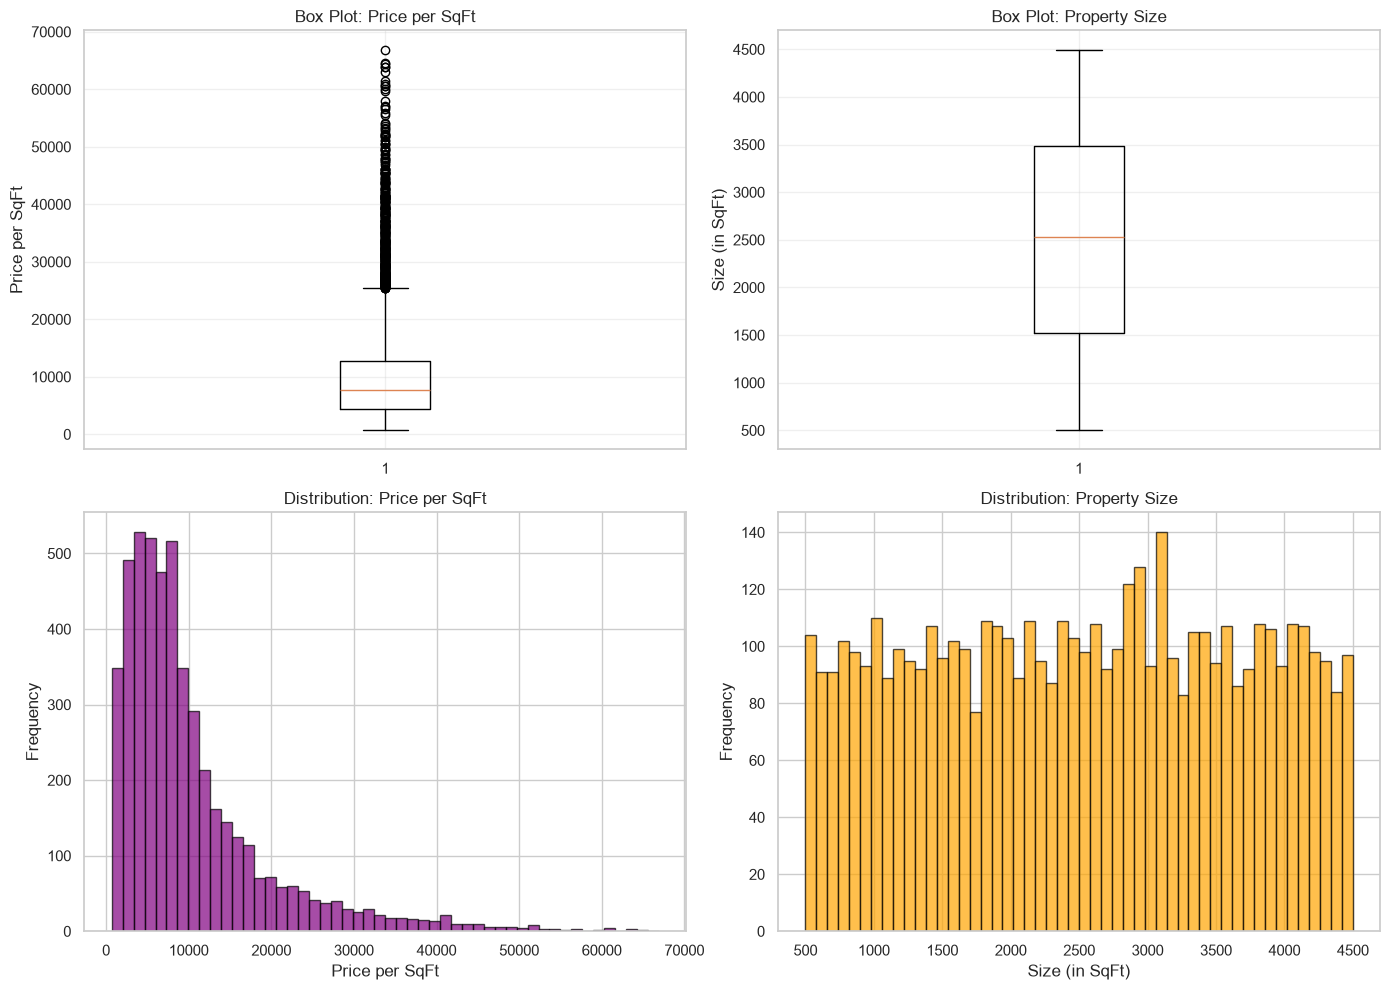

Outlier Analysis (IQR Method):
Price per SqFt outliers: 384 (7.68%)
Size outliers: 0 (0.00%)


In [106]:
# Q5: Are there any outliers in price per sqft or property size?

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Box plot for Price per SqFt
axes[0, 0].boxplot(df['Price_per_SqFt'], vert=True)
axes[0, 0].set_ylabel('Price per SqFt')
axes[0, 0].set_title('Box Plot: Price per SqFt')
axes[0, 0].grid(True, alpha=0.3)

# Box plot for Size
axes[0, 1].boxplot(df['Size_in_SqFt'], vert=True)
axes[0, 1].set_ylabel('Size (in SqFt)')
axes[0, 1].set_title('Box Plot: Property Size')
axes[0, 1].grid(True, alpha=0.3)

# Histogram for Price per SqFt
axes[1, 0].hist(df['Price_per_SqFt'], bins=50, color='purple', edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Price per SqFt')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution: Price per SqFt')

# Histogram for Size
axes[1, 1].hist(df['Size_in_SqFt'], bins=50, color='orange', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Size (in SqFt)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Distribution: Property Size')

plt.tight_layout()
plt.show()

# Calculate outliers using IQR method
Q1_price = df['Price_per_SqFt'].quantile(0.25)
Q3_price = df['Price_per_SqFt'].quantile(0.75)
IQR_price = Q3_price - Q1_price
outliers_price = df[(df['Price_per_SqFt'] < Q1_price - 1.5*IQR_price) | (df['Price_per_SqFt'] > Q3_price + 1.5*IQR_price)]

Q1_size = df['Size_in_SqFt'].quantile(0.25)
Q3_size = df['Size_in_SqFt'].quantile(0.75)
IQR_size = Q3_size - Q1_size
outliers_size = df[(df['Size_in_SqFt'] < Q1_size - 1.5*IQR_size) | (df['Size_in_SqFt'] > Q3_size + 1.5*IQR_size)]

print("Outlier Analysis (IQR Method):")
print(f"Price per SqFt outliers: {len(outliers_price)} ({len(outliers_price)/len(df)*100:.2f}%)")
print(f"Size outliers: {len(outliers_size)} ({len(outliers_size)/len(df)*100:.2f}%)")

### 6.5 Price per Square Foot by Property Type

In this section, we compare the price per square foot across different property types, such as apartments, villas, and houses.

A box plot helps us compare the distribution and variability of property prices per square foot across property types. This analysis can reveal differences in pricing patterns between property categories and help identify potential outliers.

Price per square foot provides a useful normalized measure for comparing properties of different sizes, although location and other property characteristics can also influence the results.

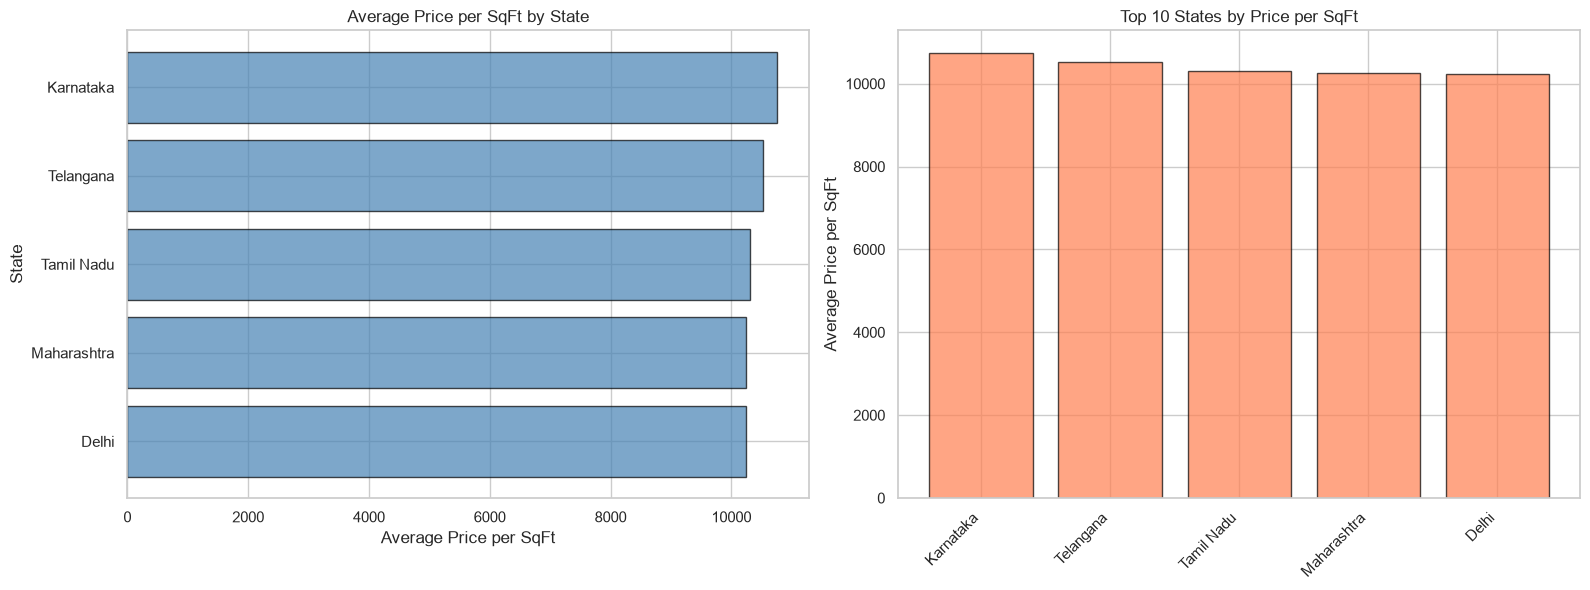

Average Price per SqFt by State (Top 10):
State
Karnataka     10,747.29
Telangana     10,516.09
Tamil Nadu    10,302.49
Maharashtra   10,247.70
Delhi         10,235.92
Name: Price_per_SqFt, dtype: float64

Average Price per SqFt by State (Bottom 10):
State
Karnataka     10,747.29
Telangana     10,516.09
Tamil Nadu    10,302.49
Maharashtra   10,247.70
Delhi         10,235.92
Name: Price_per_SqFt, dtype: float64


In [107]:
# Q6: What is the average price per sqft by state?

# Calculate average price per sqft by state
state_price = df.groupby('State')['Price_per_SqFt'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar plot
axes[0].barh(state_price.index, state_price.values, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Average Price per SqFt')
axes[0].set_ylabel('State')
axes[0].set_title('Average Price per SqFt by State')
axes[0].invert_yaxis()

# Top 10 states
top10_states = state_price.head(10)
axes[1].bar(range(len(top10_states)), top10_states.values, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_xticks(range(len(top10_states)))
axes[1].set_xticklabels(top10_states.index, rotation=45, ha='right')
axes[1].set_ylabel('Average Price per SqFt')
axes[1].set_title('Top 10 States by Price per SqFt')

plt.tight_layout()
plt.show()

print("Average Price per SqFt by State (Top 10):")
print(state_price.head(10))
print("\nAverage Price per SqFt by State (Bottom 10):")
print(state_price.tail(10))

### 6.6 Average Property Price by City

In this section, we compare average property prices across cities to understand geographical variations in the housing market.

A city-wise comparison helps identify locations with relatively higher or lower average property prices. These differences may be associated with local demand, infrastructure, amenities, and other market factors.

This analysis will help us understand the importance of location when evaluating properties for investment.

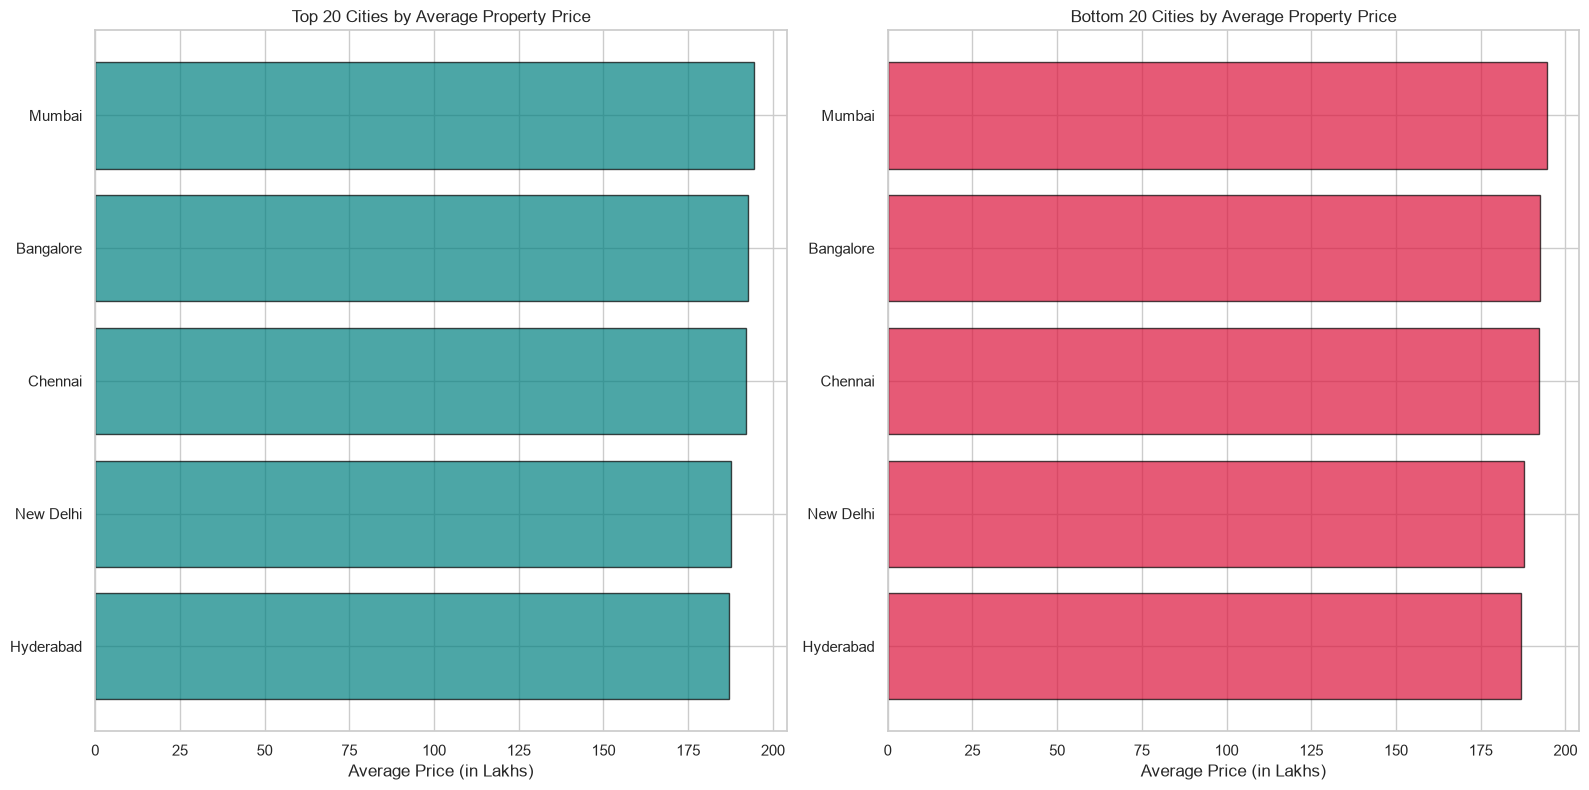

Average Property Price by City (Top 10):
City
Mumbai      194.43
Bangalore   192.62
Chennai     192.16
New Delhi   187.77
Hyderabad   186.97
Name: Price_in_Lakhs, dtype: float64

Average Property Price by City (Bottom 10):
City
Mumbai      194.43
Bangalore   192.62
Chennai     192.16
New Delhi   187.77
Hyderabad   186.97
Name: Price_in_Lakhs, dtype: float64


In [108]:
# Q7: What is the average property price by city?

city_price = df.groupby('City')['Price_in_Lakhs'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top 20 cities
top20_cities = city_price.head(20)
axes[0].barh(range(len(top20_cities)), top20_cities.values, color='teal', edgecolor='black', alpha=0.7)
axes[0].set_yticks(range(len(top20_cities)))
axes[0].set_yticklabels(top20_cities.index)
axes[0].set_xlabel('Average Price (in Lakhs)')
axes[0].set_title('Top 20 Cities by Average Property Price')
axes[0].invert_yaxis()

# Bottom 20 cities
bottom20_cities = city_price.tail(20)
axes[1].barh(range(len(bottom20_cities)), bottom20_cities.values, color='crimson', edgecolor='black', alpha=0.7)
axes[1].set_yticks(range(len(bottom20_cities)))
axes[1].set_yticklabels(bottom20_cities.index)
axes[1].set_xlabel('Average Price (in Lakhs)')
axes[1].set_title('Bottom 20 Cities by Average Property Price')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("Average Property Price by City (Top 10):")
print(city_price.head(10))
print("\nAverage Property Price by City (Bottom 10):")
print(city_price.tail(10))

Property Age Summary:


count   250,000.00
mean         19.48
std           9.81
min           3.00
25%          11.00
50%          19.00
75%          28.00
max          36.00
Name: Age_of_Property, dtype: float64

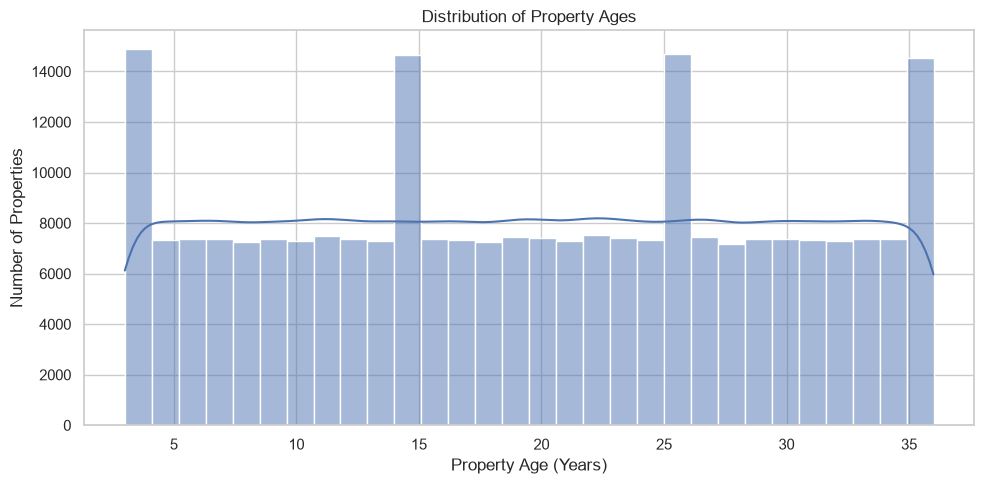

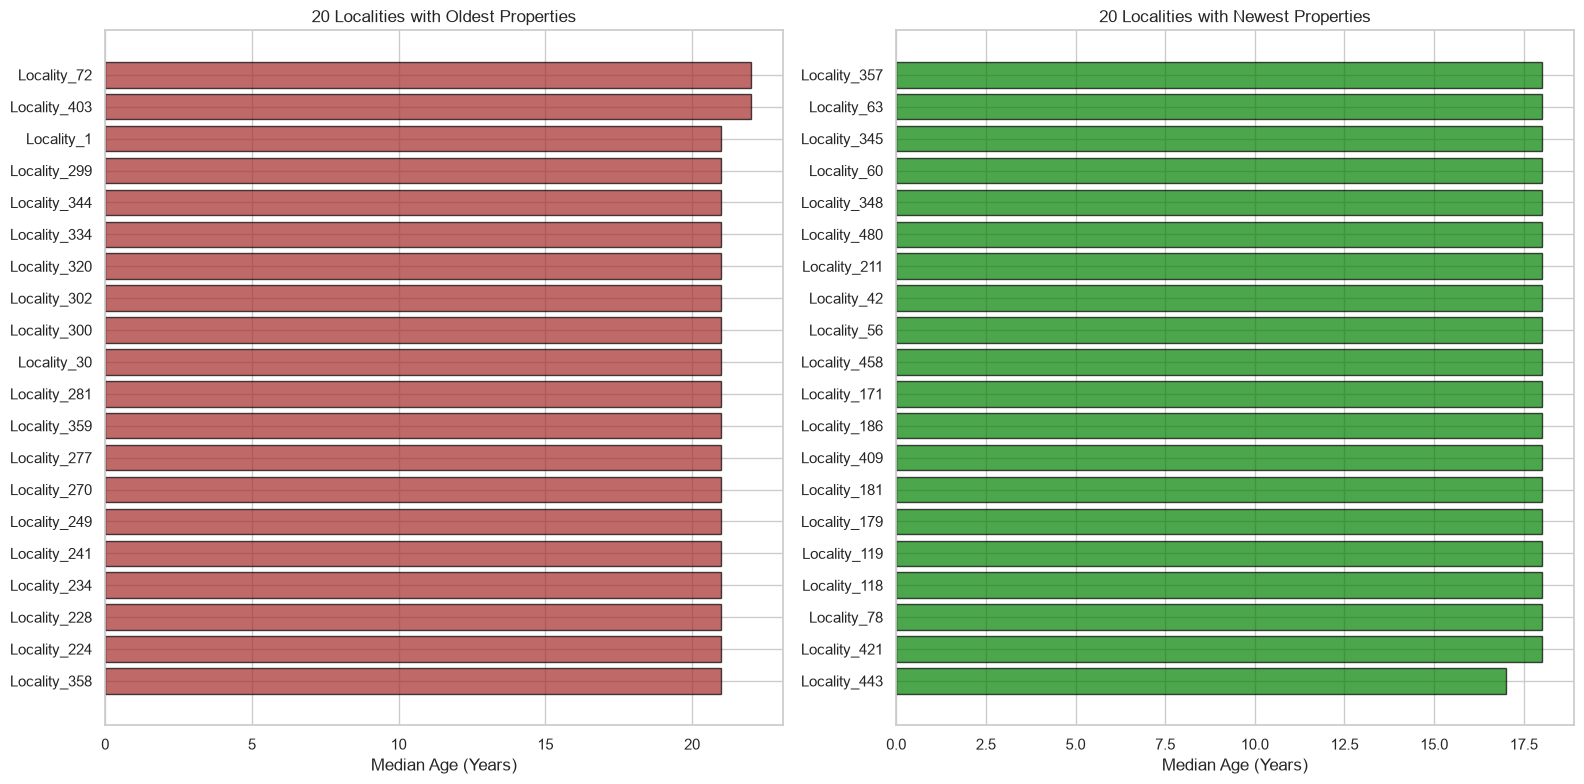

Median Age Statistics:
Overall Median Age: 19.00 years
Oldest Locality: Locality_72 (22.00 years)
Newest Locality: Locality_443 (17.00 years)
Age Range across Localities: 17.00 to 22.00 years
Top 10 Localities by Median Property Age:


Locality
Locality_72    22.00
Locality_403   22.00
Locality_1     21.00
Locality_299   21.00
Locality_344   21.00
Locality_334   21.00
Locality_320   21.00
Locality_302   21.00
Locality_300   21.00
Locality_30    21.00
Name: Age_of_Property, dtype: float64

In [7]:
# ============================================================
# Q8: What is the median age of properties by locality?
# ============================================================

# Display summary statistics for property age
# Property age summary
print("Property Age Summary:")
display(df["Age_of_Property"].describe())

# Distribution of property ages
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="Age_of_Property",
    bins=30,
    kde=True
)
plt.title("Distribution of Property Ages")
plt.xlabel("Property Age (Years)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

# Median property age by locality
locality_median_age = (
    df.groupby("Locality")["Age_of_Property"]
    .median()
    .sort_values(ascending=False)
)

# Top 20 oldest and newest localities
top20_age = locality_median_age.head(20)
bottom20_age = locality_median_age.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(
    range(len(top20_age)),
    top20_age.values,
    color="brown",
    edgecolor="black",
    alpha=0.7
)
axes[0].set_yticks(range(len(top20_age)))
axes[0].set_yticklabels(top20_age.index)
axes[0].set_xlabel("Median Age (Years)")
axes[0].set_title("20 Localities with Oldest Properties")
axes[0].invert_yaxis()

axes[1].barh(
    range(len(bottom20_age)),
    bottom20_age.values,
    color="green",
    edgecolor="black",
    alpha=0.7
)
axes[1].set_yticks(range(len(bottom20_age)))
axes[1].set_yticklabels(bottom20_age.index)
axes[1].set_xlabel("Median Age (Years)")
axes[1].set_title("20 Localities with Newest Properties")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Summary by locality
print("Median Age Statistics:")
print(f"Overall Median Age: {df['Age_of_Property'].median():.2f} years")
print(
    f"Oldest Locality: {locality_median_age.index[0]} "
    f"({locality_median_age.iloc[0]:.2f} years)"
)
print(
    f"Newest Locality: {locality_median_age.index[-1]} "
    f"({locality_median_age.iloc[-1]:.2f} years)"
)
print(
    f"Age Range across Localities: "
    f"{locality_median_age.min():.2f} to "
    f"{locality_median_age.max():.2f} years"
)

print("Top 10 Localities by Median Property Age:")
display(locality_median_age.head(10))

BHK Distribution Across Cities (First 10 Cities):


BHK,1,2,3,4,5
City,,,,,
Ahmedabad,1264,1267,1272,1258,1350
Amritsar,1284,1239,1234,1224,1240
Bangalore,839,823,802,833,847
Bhopal,1238,1235,1255,1259,1297
Bhubaneswar,1236,1293,1299,1217,1278
Bilaspur,1210,1252,1275,1268,1258
Chennai,1263,1232,1183,1257,1233
Coimbatore,1236,1301,1317,1345,1262
Cuttack,1320,1292,1301,1236,1209


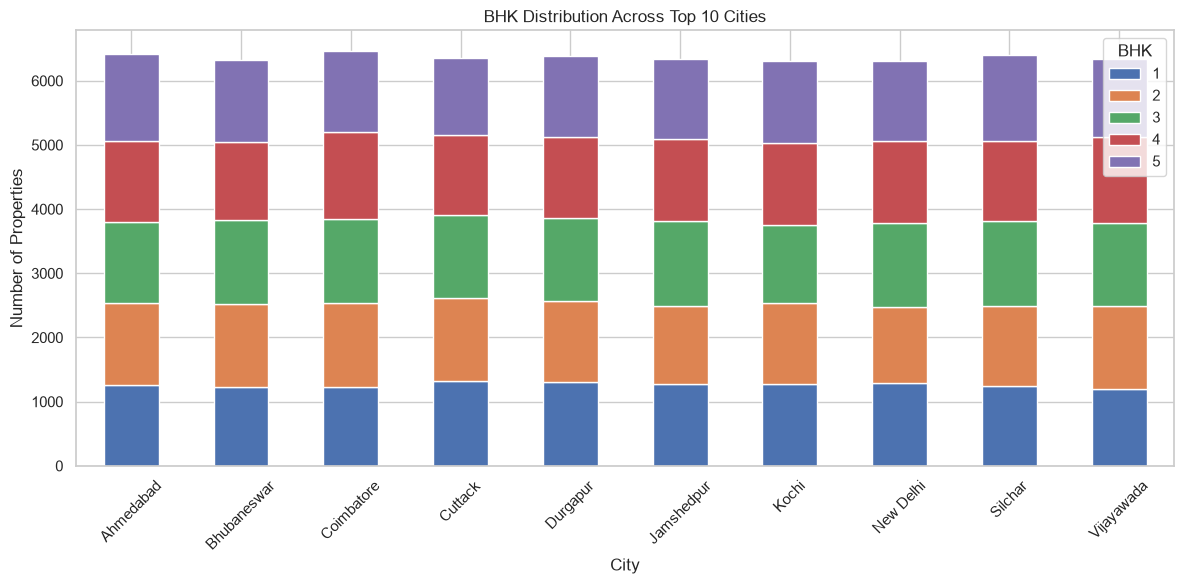

In [8]:
# ============================================================
#  Q9: How is BHK distributed across cities?
# ============================================================

# Create a cross-tabulation of BHK configurations by city
bhk_city = pd.crosstab(df["City"], df["BHK"])

# Display the distribution for the first 10 cities
print("BHK Distribution Across Cities (First 10 Cities):")
display(bhk_city.head(10))

# Plot the BHK distribution for the 10 cities with the most records
top_cities = df["City"].value_counts().head(10).index

bhk_top_cities = pd.crosstab(
    df.loc[df["City"].isin(top_cities), "City"],
    df.loc[df["City"].isin(top_cities), "BHK"]
)

# Create a stacked bar chart
bhk_top_cities.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("BHK Distribution Across Top 10 Cities")
plt.xlabel("City")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)
plt.legend(title="BHK")
plt.tight_layout()
plt.show()

Top 5 Most Expensive Localities:
Locality
Locality_395   275.43
Locality_366   273.41
Locality_497   270.00
Locality_360   269.81
Locality_203   269.03
Name: Price_in_Lakhs, dtype: float64


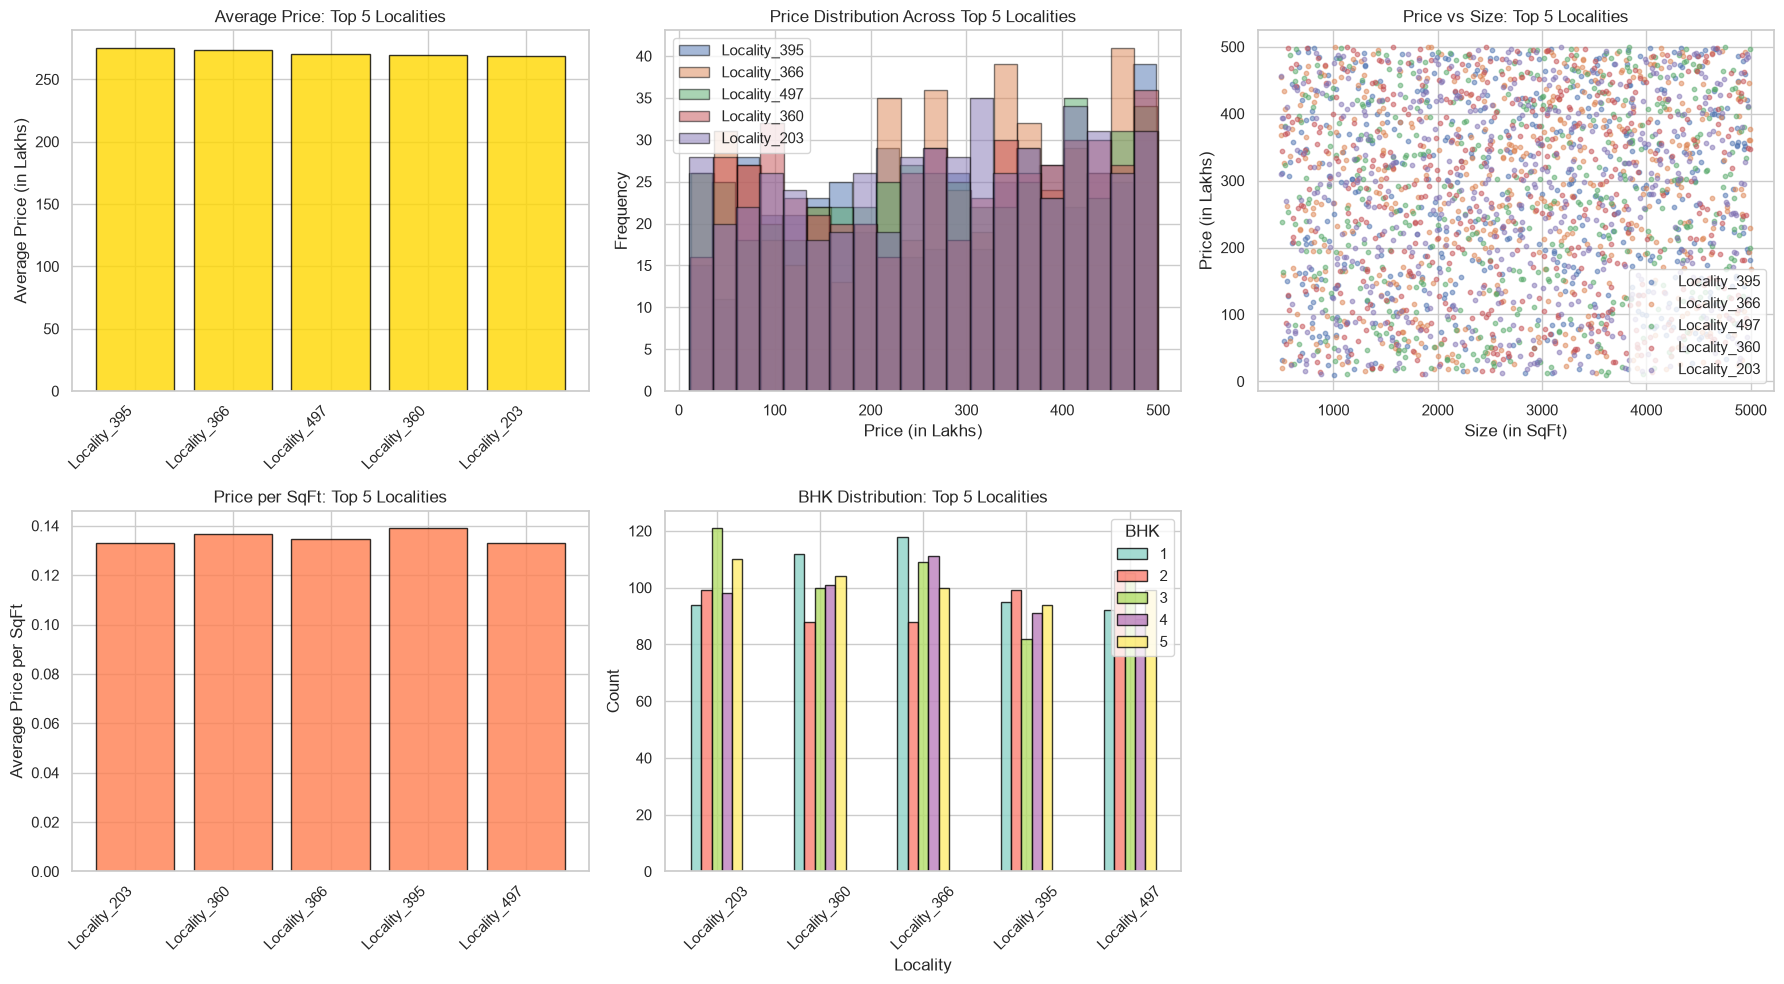


Detailed Statistics for Top 5 Localities:
             Price_in_Lakhs                                                  \
                      count   mean    std   min    25%    50%    75%    max   
Locality                                                                      
Locality_203         522.00 269.03 141.19 10.69 144.45 280.32 397.34 498.91   
Locality_360         505.00 269.81 145.42 11.61 133.89 278.85 398.60 499.78   
Locality_366         526.00 273.41 143.97 12.46 150.27 282.33 392.61 499.40   
Locality_395         461.00 275.43 142.44 10.37 155.09 282.68 398.90 498.24   
Locality_497         491.00 270.00 144.13 10.08 151.99 273.69 401.76 499.35   

             Price_per_SqFt                                    Size_in_SqFt  \
                      count mean  std  min  25%  50%  75%  max        count   
Locality                                                                      
Locality_203         522.00 0.13 0.13 0.00 0.05 0.10 0.16 0.91       522.00   
Locality

In [9]:
# Q10: What are the price trends for the top 5 most expensive localities?

# Find top 5 most expensive localities
top5_localities = df.groupby('Locality')['Price_in_Lakhs'].mean().sort_values(ascending=False).head(5)

print("Top 5 Most Expensive Localities:")
print(top5_localities)

# Filter data for these localities
top5_data = df[df['Locality'].isin(top5_localities.index)]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Plot 1: Average price by locality
axes[0].bar(range(len(top5_localities)), top5_localities.values, color='gold', edgecolor='black', alpha=0.8)
axes[0].set_xticks(range(len(top5_localities)))
axes[0].set_xticklabels(top5_localities.index, rotation=45, ha='right')
axes[0].set_ylabel('Average Price (in Lakhs)')
axes[0].set_title('Average Price: Top 5 Localities')

# Plot 2: Price distribution for each locality
for locality in top5_localities.index:
    locality_data = top5_data[top5_data['Locality'] == locality]['Price_in_Lakhs']
    axes[1].hist(locality_data, alpha=0.5, label=locality, bins=20, edgecolor='black')
axes[1].set_xlabel('Price (in Lakhs)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Price Distribution Across Top 5 Localities')
axes[1].legend()

# Plot 3: Price vs Size for top localities
for locality in top5_localities.index:
    locality_data = top5_data[top5_data['Locality'] == locality]
    axes[2].scatter(locality_data['Size_in_SqFt'], locality_data['Price_in_Lakhs'],
                   alpha=0.5, label=locality, s=10)
axes[2].set_xlabel('Size (in SqFt)')
axes[2].set_ylabel('Price (in Lakhs)')
axes[2].set_title('Price vs Size: Top 5 Localities')
axes[2].legend()

# Plot 4: Price per sqft
price_per_sqft_top5 = top5_data.groupby('Locality')['Price_per_SqFt'].mean()
axes[3].bar(range(len(price_per_sqft_top5)), price_per_sqft_top5.values, color='coral', edgecolor='black', alpha=0.8)
axes[3].set_xticks(range(len(price_per_sqft_top5)))
axes[3].set_xticklabels(price_per_sqft_top5.index, rotation=45, ha='right')
axes[3].set_ylabel('Average Price per SqFt')
axes[3].set_title('Price per SqFt: Top 5 Localities')

# Plot 5: BHK distribution
bhk_dist = top5_data.groupby('Locality')['BHK'].value_counts().unstack(fill_value=0)
bhk_dist.plot(kind='bar', ax=axes[4], colormap='Set3', edgecolor='black', alpha=0.8)
axes[4].set_xlabel('Locality')
axes[4].set_ylabel('Count')
axes[4].set_title('BHK Distribution: Top 5 Localities')
axes[4].tick_params(axis='x', rotation=45)
axes[4].legend(title='BHK')

# Remove extra subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

print("\nDetailed Statistics for Top 5 Localities:")
print(top5_data.groupby('Locality')[['Price_in_Lakhs', 'Price_per_SqFt', 'Size_in_SqFt', 'BHK']].describe())

Correlation Matrix:


,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
BHK,1.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
Size_in_SqFt,-0.00,1.00,-0.00,-0.61,0.00,-0.00,-0.00,-0.00,0.00,-0.00
Price_in_Lakhs,-0.00,-0.00,1.00,0.56,0.00,-0.00,0.00,-0.00,0.00,-0.00
Price_per_SqFt,0.00,-0.61,0.56,1.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00
Year_Built,0.00,0.00,0.00,-0.00,1.00,-0.00,0.00,-1.00,-0.00,-0.00
Floor_No,0.00,-0.00,-0.00,-0.00,-0.00,1.00,0.00,0.00,-0.00,0.00
Total_Floors,-0.00,-0.00,0.00,0.00,0.00,0.00,1.00,-0.00,-0.00,-0.01
Age_of_Property,-0.00,-0.00,-0.00,0.00,-1.00,0.00,-0.00,1.00,0.00,0.00
Nearby_Schools,-0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,1.00,-0.00
Nearby_Hospitals,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.01,0.00,-0.00,1.00


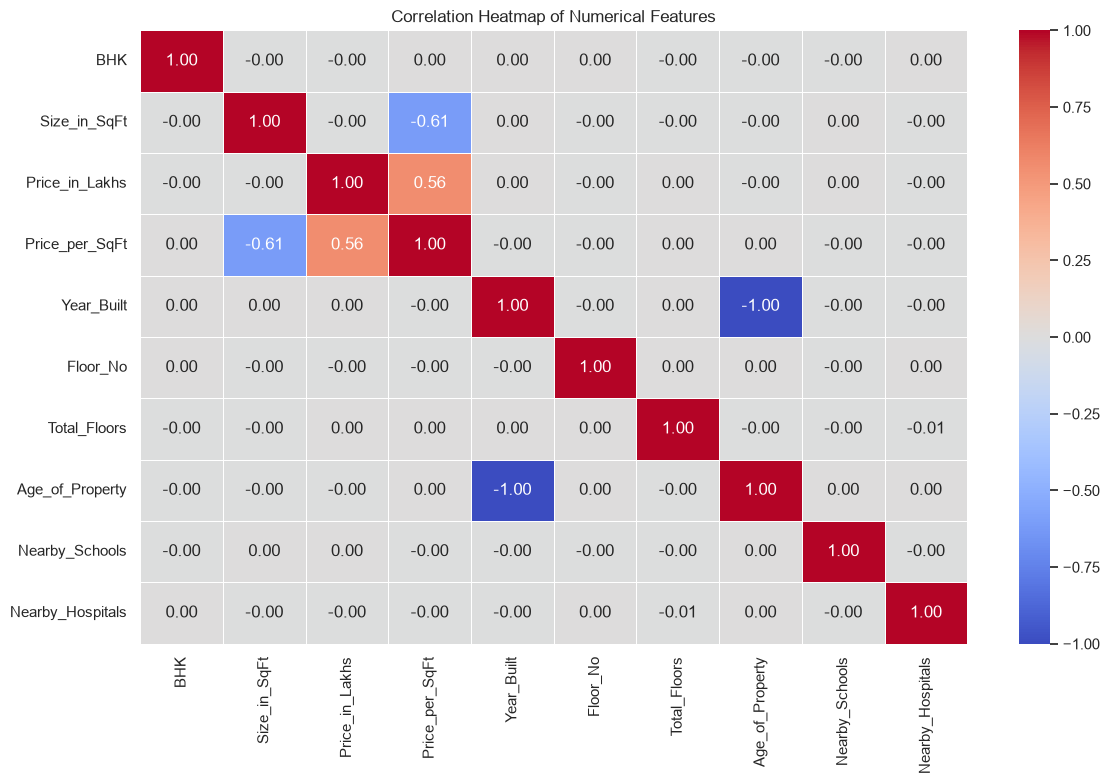

In [10]:
# ============================================================
# Q11: How are numeric features correlated with each other?
# ============================================================

# Select numerical columns and exclude the unique property ID
correlation_data = df.select_dtypes(include=np.number).drop(
    columns=["ID"],
    errors="ignore"
)

# Calculate the Pearson correlation matrix
correlation_matrix = correlation_data.corr()

# Display the correlation matrix
print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Plot the correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

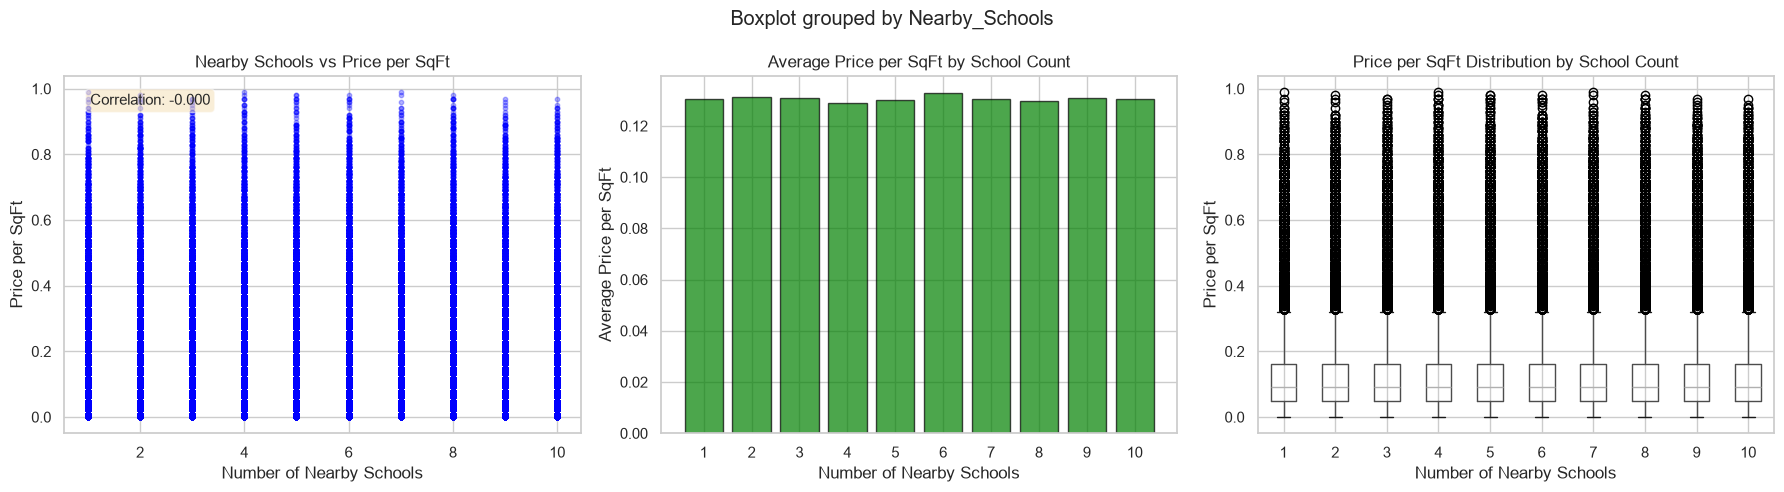

Price per SqFt Statistics by Nearby Schools:
                mean  median  std  count
Nearby_Schools                          
1               0.13    0.09 0.13  25360
2               0.13    0.09 0.13  24851
3               0.13    0.09 0.13  25045
4               0.13    0.09 0.13  24739
5               0.13    0.09 0.13  25023
6               0.13    0.09 0.13  24824
7               0.13    0.09 0.13  24808
8               0.13    0.09 0.13  25290
9               0.13    0.09 0.13  24823
10              0.13    0.09 0.13  25237


In [12]:
# ============================================================
# Q12: How do nearby schools relate to price per sqft?
# ============================================================

# Calculate the correlation between nearby schools and price per square foot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot
axes[0].scatter(df['Nearby_Schools'], df['Price_per_SqFt'], alpha=0.3, s=10, color='blue')
axes[0].set_xlabel('Number of Nearby Schools')
axes[0].set_ylabel('Price per SqFt')
axes[0].set_title('Nearby Schools vs Price per SqFt')
corr = df['Nearby_Schools'].corr(df['Price_per_SqFt'])
axes[0].text(0.05, 0.95, f'Correlation: {corr:.3f}',
             transform=axes[0].transAxes, fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Average price per sqft by number of schools
avg_price_schools = df.groupby('Nearby_Schools')['Price_per_SqFt'].mean()
axes[1].bar(avg_price_schools.index, avg_price_schools.values, color='green', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Number of Nearby Schools')
axes[1].set_ylabel('Average Price per SqFt')
axes[1].set_title('Average Price per SqFt by School Count')
axes[1].set_xticks(avg_price_schools.index)

# Box plot
df.boxplot(column='Price_per_SqFt', by='Nearby_Schools', ax=axes[2])
axes[2].set_xlabel('Number of Nearby Schools')
axes[2].set_ylabel('Price per SqFt')
axes[2].set_title('Price per SqFt Distribution by School Count')
plt.sca(axes[2])

plt.tight_layout()
plt.show()

print("Price per SqFt Statistics by Nearby Schools:")
print(df.groupby('Nearby_Schools')['Price_per_SqFt'].agg(['mean', 'median', 'std', 'count']))

Correlation between Nearby Hospitals and Price per SqFt: -0.0001


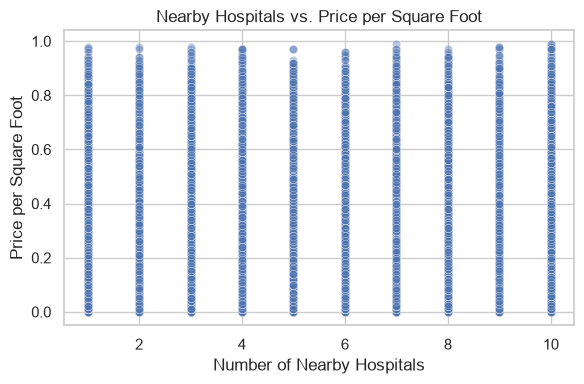

In [13]:
# ============================================================
# Q13: How do nearby hospitals relate to price per sqft?
# ============================================================

# Calculate the correlation between nearby hospitals
# and property price per square foot
hospitals_correlation = df["Nearby_Hospitals"].corr(
    df["Price_per_SqFt"]
)

print(
    "Correlation between Nearby Hospitals and Price per SqFt:",
    round(hospitals_correlation, 4)
)

# Create a scatter plot to visualize the relationship
plt.figure(figsize=(6,4))

sns.scatterplot(
    data=df,
    x="Nearby_Hospitals",
    y="Price_per_SqFt",
    alpha=0.4
)

# Add chart title and axis labels
plt.title("Nearby Hospitals vs. Price per Square Foot")
plt.xlabel("Number of Nearby Hospitals")
plt.ylabel("Price per Square Foot")

# Display the plot
plt.tight_layout()
plt.show()

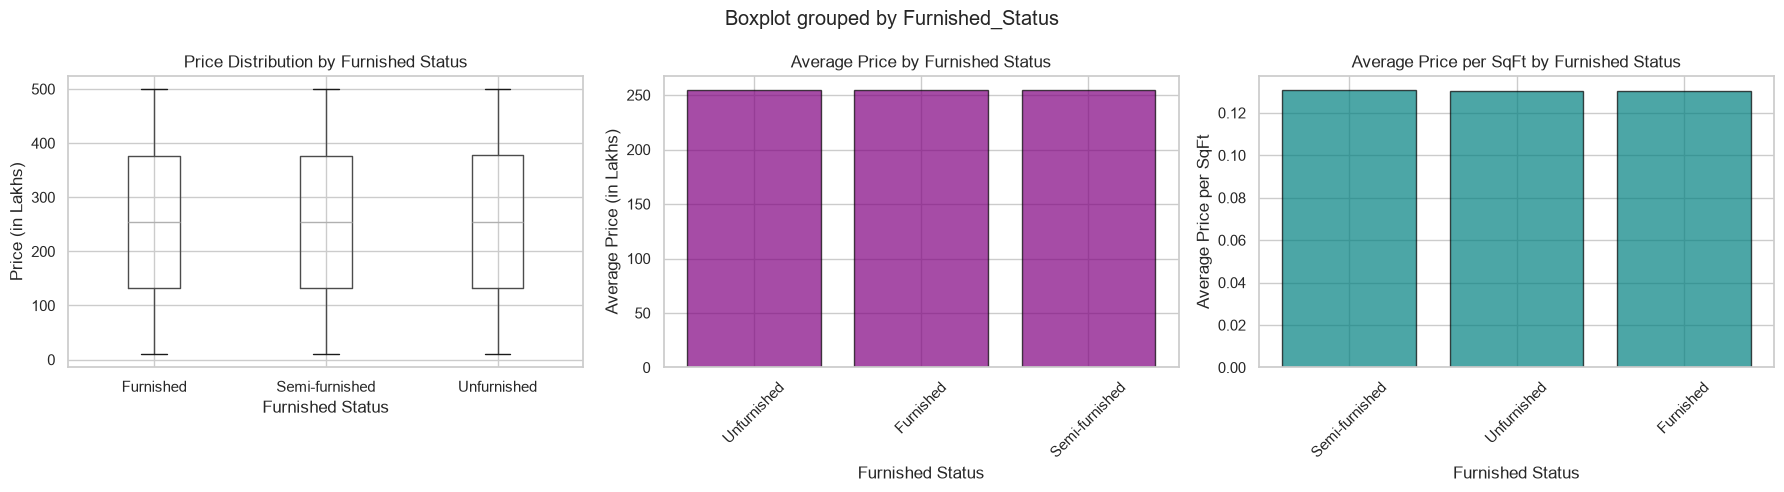

Price Statistics by Furnished Status:
                   mean  median    std  count
Furnished_Status                             
Furnished        254.45  253.56 141.20  83218
Semi-furnished   254.33  253.81 141.45  83374
Unfurnished      254.98  254.19 141.40  83408

Price per SqFt Statistics by Furnished Status:
                  mean  median  std  count
Furnished_Status                          
Furnished         0.13    0.09 0.13  83218
Semi-furnished    0.13    0.09 0.13  83374
Unfurnished       0.13    0.09 0.13  83408


In [14]:
# ============================================================
# Q14: How does price vary by furnished status?
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot for price
df.boxplot(column='Price_in_Lakhs', by='Furnished_Status', ax=axes[0])
axes[0].set_xlabel('Furnished Status')
axes[0].set_ylabel('Price (in Lakhs)')
axes[0].set_title('Price Distribution by Furnished Status')
plt.sca(axes[0])

# Bar plot for average price
avg_price_furnished = df.groupby('Furnished_Status')['Price_in_Lakhs'].mean().sort_values(ascending=False)
axes[1].bar(avg_price_furnished.index, avg_price_furnished.values, color='purple', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Furnished Status')
axes[1].set_ylabel('Average Price (in Lakhs)')
axes[1].set_title('Average Price by Furnished Status')
axes[1].tick_params(axis='x', rotation=45)

# Price per sqft by furnished status
avg_price_sqft_furnished = df.groupby('Furnished_Status')['Price_per_SqFt'].mean().sort_values(ascending=False)
axes[2].bar(avg_price_sqft_furnished.index, avg_price_sqft_furnished.values, color='teal', edgecolor='black', alpha=0.7)
axes[2].set_xlabel('Furnished Status')
axes[2].set_ylabel('Average Price per SqFt')
axes[2].set_title('Average Price per SqFt by Furnished Status')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Price Statistics by Furnished Status:")
print(df.groupby('Furnished_Status')['Price_in_Lakhs'].agg(['mean', 'median', 'std', 'count']))
print("\nPrice per SqFt Statistics by Furnished Status:")
print(df.groupby('Furnished_Status')['Price_per_SqFt'].agg(['mean', 'median', 'std', 'count']))

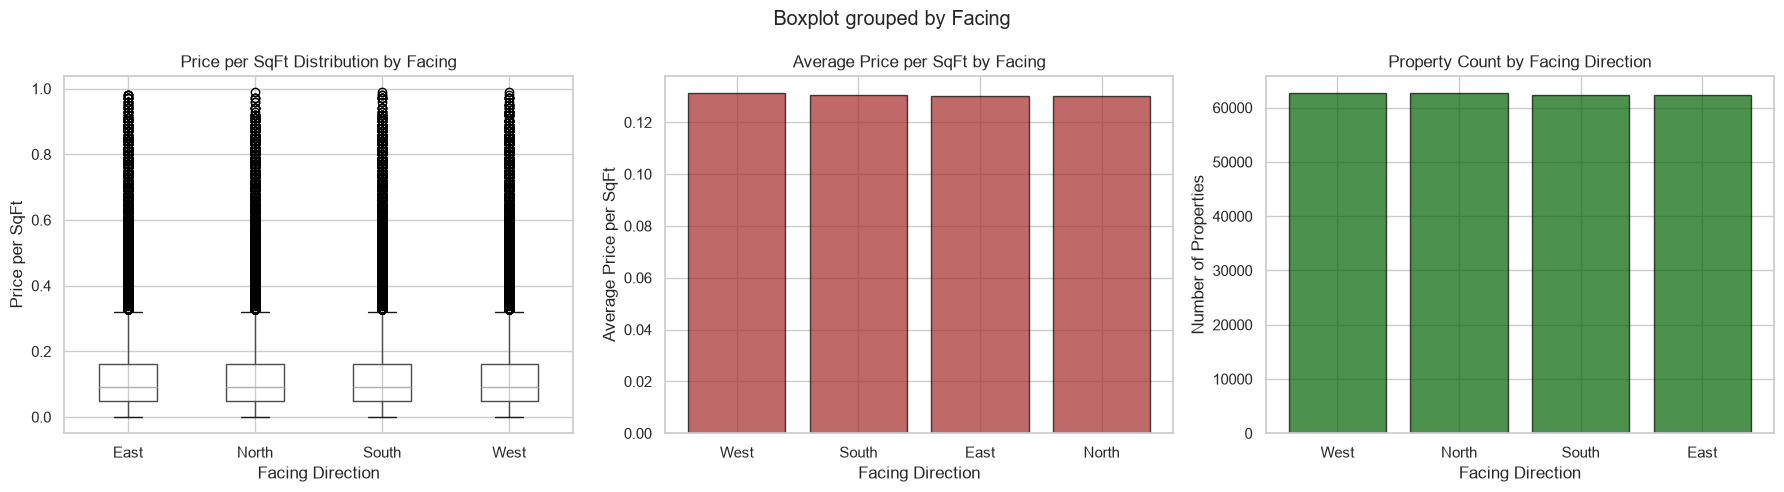

Price per SqFt Statistics by Facing Direction:
        mean  median  std  count
Facing                          
East    0.13    0.09 0.13  62269
North   0.13    0.09 0.13  62637
South   0.13    0.09 0.13  62337
West    0.13    0.09 0.13  62757

Price Statistics by Facing Direction:
         mean  median    std
Facing                      
East   254.49  253.50 141.33
North  254.73  253.86 141.33
South  254.08  253.18 141.16
West   255.04  255.03 141.58


In [15]:
# Q15: How does price per sqft vary by property facing direction?

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
df.boxplot(column='Price_per_SqFt', by='Facing', ax=axes[0])
axes[0].set_xlabel('Facing Direction')
axes[0].set_ylabel('Price per SqFt')
axes[0].set_title('Price per SqFt Distribution by Facing')
plt.sca(axes[0])

# Bar plot for average price per sqft
avg_price_facing = df.groupby('Facing')['Price_per_SqFt'].mean().sort_values(ascending=False)
axes[1].bar(avg_price_facing.index, avg_price_facing.values, color='brown', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Facing Direction')
axes[1].set_ylabel('Average Price per SqFt')
axes[1].set_title('Average Price per SqFt by Facing')

# Count of properties by facing
facing_count = df['Facing'].value_counts()
axes[2].bar(facing_count.index, facing_count.values, color='darkgreen', edgecolor='black', alpha=0.7)
axes[2].set_xlabel('Facing Direction')
axes[2].set_ylabel('Number of Properties')
axes[2].set_title('Property Count by Facing Direction')

plt.tight_layout()
plt.show()

print("Price per SqFt Statistics by Facing Direction:")
print(df.groupby('Facing')['Price_per_SqFt'].agg(['mean', 'median', 'std', 'count']))
print("\nPrice Statistics by Facing Direction:")
print(df.groupby('Facing')['Price_in_Lakhs'].agg(['mean', 'median', 'std']))

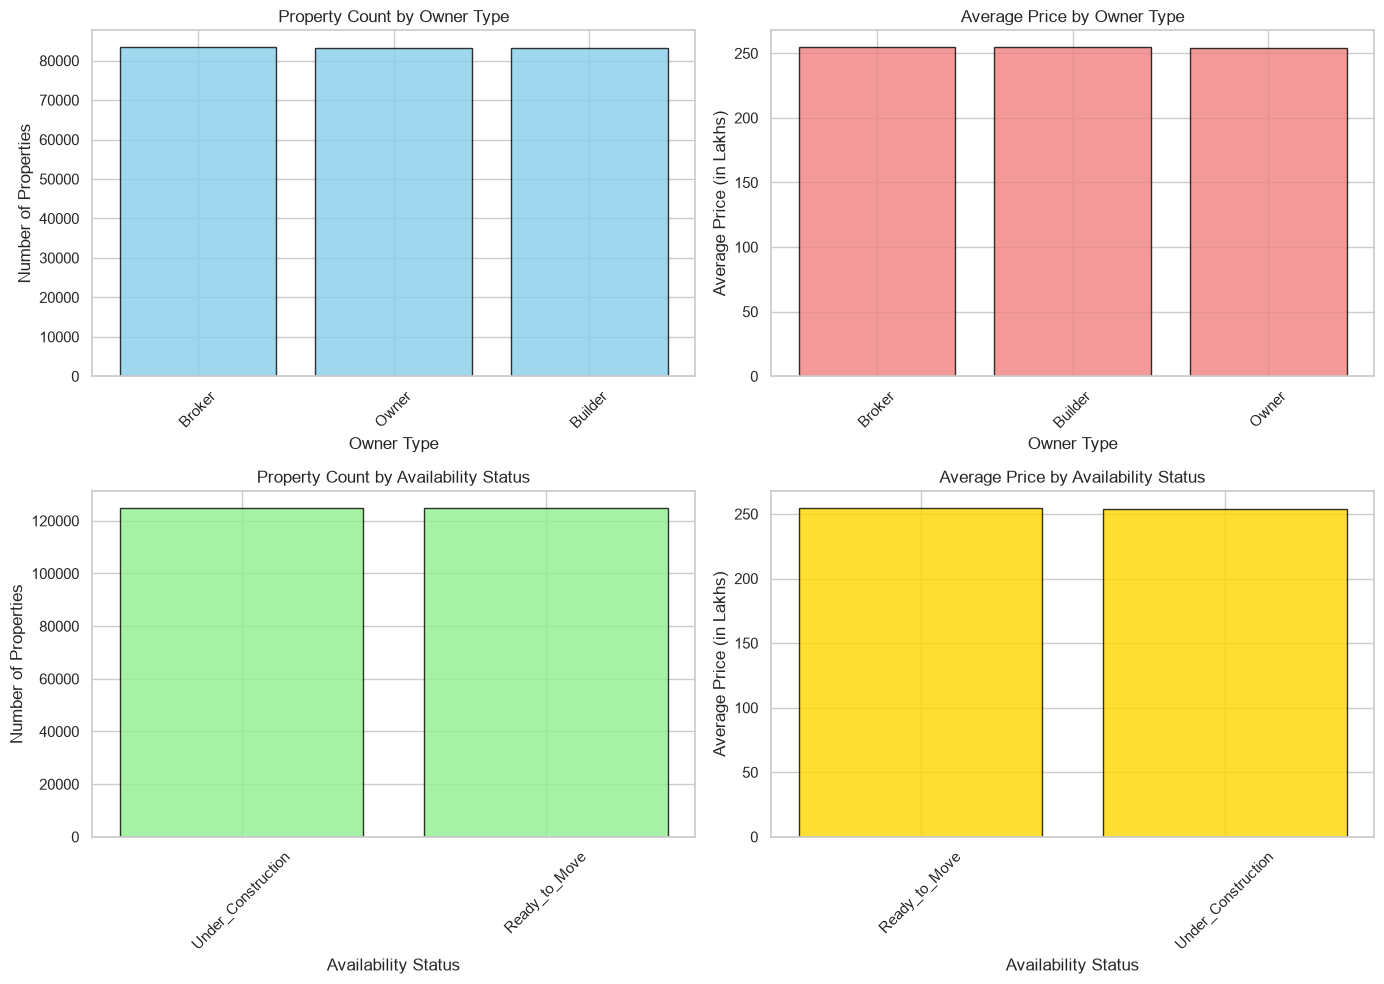

Owner Type Distribution:
Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64

Availability Status Distribution:
Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64

Price Statistics by Owner Type:
             mean  median    std
Owner_Type                      
Broker     254.91  254.90 141.54
Builder    254.59  253.67 141.19
Owner      254.25  253.00 141.31

Price Statistics by Availability Status:
                      mean  median    std
Availability_Status                      
Ready_to_Move       254.98  254.31 141.09
Under_Construction  254.19  253.48 141.61


In [16]:
# Q16: How many properties belong to each owner type?
# Q17: How many properties are available under each availability status?

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Owner type count
owner_count = df['Owner_Type'].value_counts()
axes[0, 0].bar(owner_count.index, owner_count.values, color='skyblue', edgecolor='black', alpha=0.8)
axes[0, 0].set_xlabel('Owner Type')
axes[0, 0].set_ylabel('Number of Properties')
axes[0, 0].set_title('Property Count by Owner Type')
axes[0, 0].tick_params(axis='x', rotation=45)

# Price by owner type
avg_price_owner = df.groupby('Owner_Type')['Price_in_Lakhs'].mean().sort_values(ascending=False)
axes[0, 1].bar(avg_price_owner.index, avg_price_owner.values, color='lightcoral', edgecolor='black', alpha=0.8)
axes[0, 1].set_xlabel('Owner Type')
axes[0, 1].set_ylabel('Average Price (in Lakhs)')
axes[0, 1].set_title('Average Price by Owner Type')
axes[0, 1].tick_params(axis='x', rotation=45)

# Availability status count
availability_count = df['Availability_Status'].value_counts()
axes[1, 0].bar(availability_count.index, availability_count.values, color='lightgreen', edgecolor='black', alpha=0.8)
axes[1, 0].set_xlabel('Availability Status')
axes[1, 0].set_ylabel('Number of Properties')
axes[1, 0].set_title('Property Count by Availability Status')
axes[1, 0].tick_params(axis='x', rotation=45)

# Price by availability status
avg_price_availability = df.groupby('Availability_Status')['Price_in_Lakhs'].mean().sort_values(ascending=False)
axes[1, 1].bar(avg_price_availability.index, avg_price_availability.values, color='gold', edgecolor='black', alpha=0.8)
axes[1, 1].set_xlabel('Availability Status')
axes[1, 1].set_ylabel('Average Price (in Lakhs)')
axes[1, 1].set_title('Average Price by Availability Status')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Owner Type Distribution:")
print(df['Owner_Type'].value_counts())
print("\nAvailability Status Distribution:")
print(df['Availability_Status'].value_counts())
print("\nPrice Statistics by Owner Type:")
print(df.groupby('Owner_Type')['Price_in_Lakhs'].agg(['mean', 'median', 'std']))
print("\nPrice Statistics by Availability Status:")
print(df.groupby('Availability_Status')['Price_in_Lakhs'].agg(['mean', 'median', 'std']))

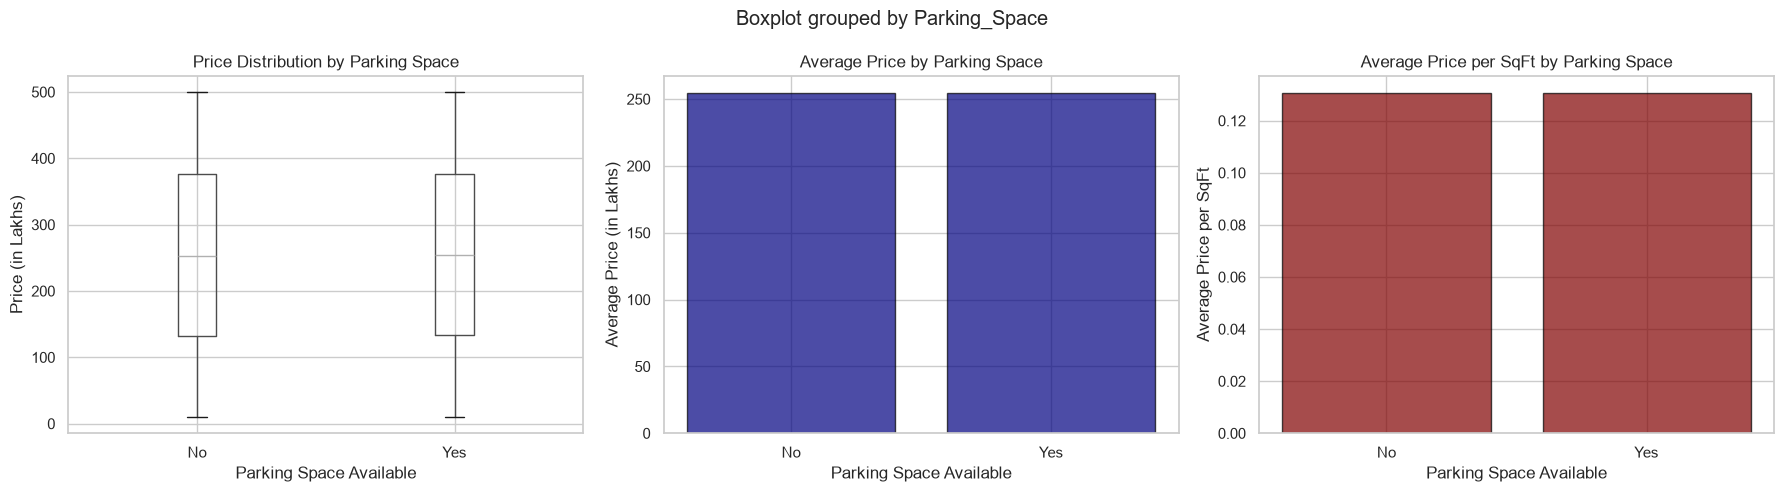

Property Count by Parking Space:
Parking_Space
No     125456
Yes    124544
Name: count, dtype: int64

Price Statistics by Parking Space:
                mean  median    std   count
Parking_Space                              
No            254.43  253.37 141.49  125456
Yes           254.75  254.36 141.21  124544

Price per SqFt Statistics by Parking Space:
               mean  median  std
Parking_Space                   
No             0.13    0.09 0.13
Yes            0.13    0.09 0.13


In [17]:
# Q18: Does parking space affect property price?

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Price distribution by parking space
df.boxplot(column='Price_in_Lakhs', by='Parking_Space', ax=axes[0])
axes[0].set_xlabel('Parking Space Available')
axes[0].set_ylabel('Price (in Lakhs)')
axes[0].set_title('Price Distribution by Parking Space')
plt.sca(axes[0])

# Average price by parking space
avg_price_parking = df.groupby('Parking_Space')['Price_in_Lakhs'].mean()
axes[1].bar(avg_price_parking.index, avg_price_parking.values, color='navy', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Parking Space Available')
axes[1].set_ylabel('Average Price (in Lakhs)')
axes[1].set_title('Average Price by Parking Space')

# Price per sqft by parking space
avg_price_sqft_parking = df.groupby('Parking_Space')['Price_per_SqFt'].mean()
axes[2].bar(avg_price_sqft_parking.index, avg_price_sqft_parking.values, color='maroon', edgecolor='black', alpha=0.7)
axes[2].set_xlabel('Parking Space Available')
axes[2].set_ylabel('Average Price per SqFt')
axes[2].set_title('Average Price per SqFt by Parking Space')

plt.tight_layout()
plt.show()

print("Property Count by Parking Space:")
print(df['Parking_Space'].value_counts())
print("\nPrice Statistics by Parking Space:")
print(df.groupby('Parking_Space')['Price_in_Lakhs'].agg(['mean', 'median', 'std', 'count']))
print("\nPrice per SqFt Statistics by Parking Space:")
print(df.groupby('Parking_Space')['Price_per_SqFt'].agg(['mean', 'median', 'std']))

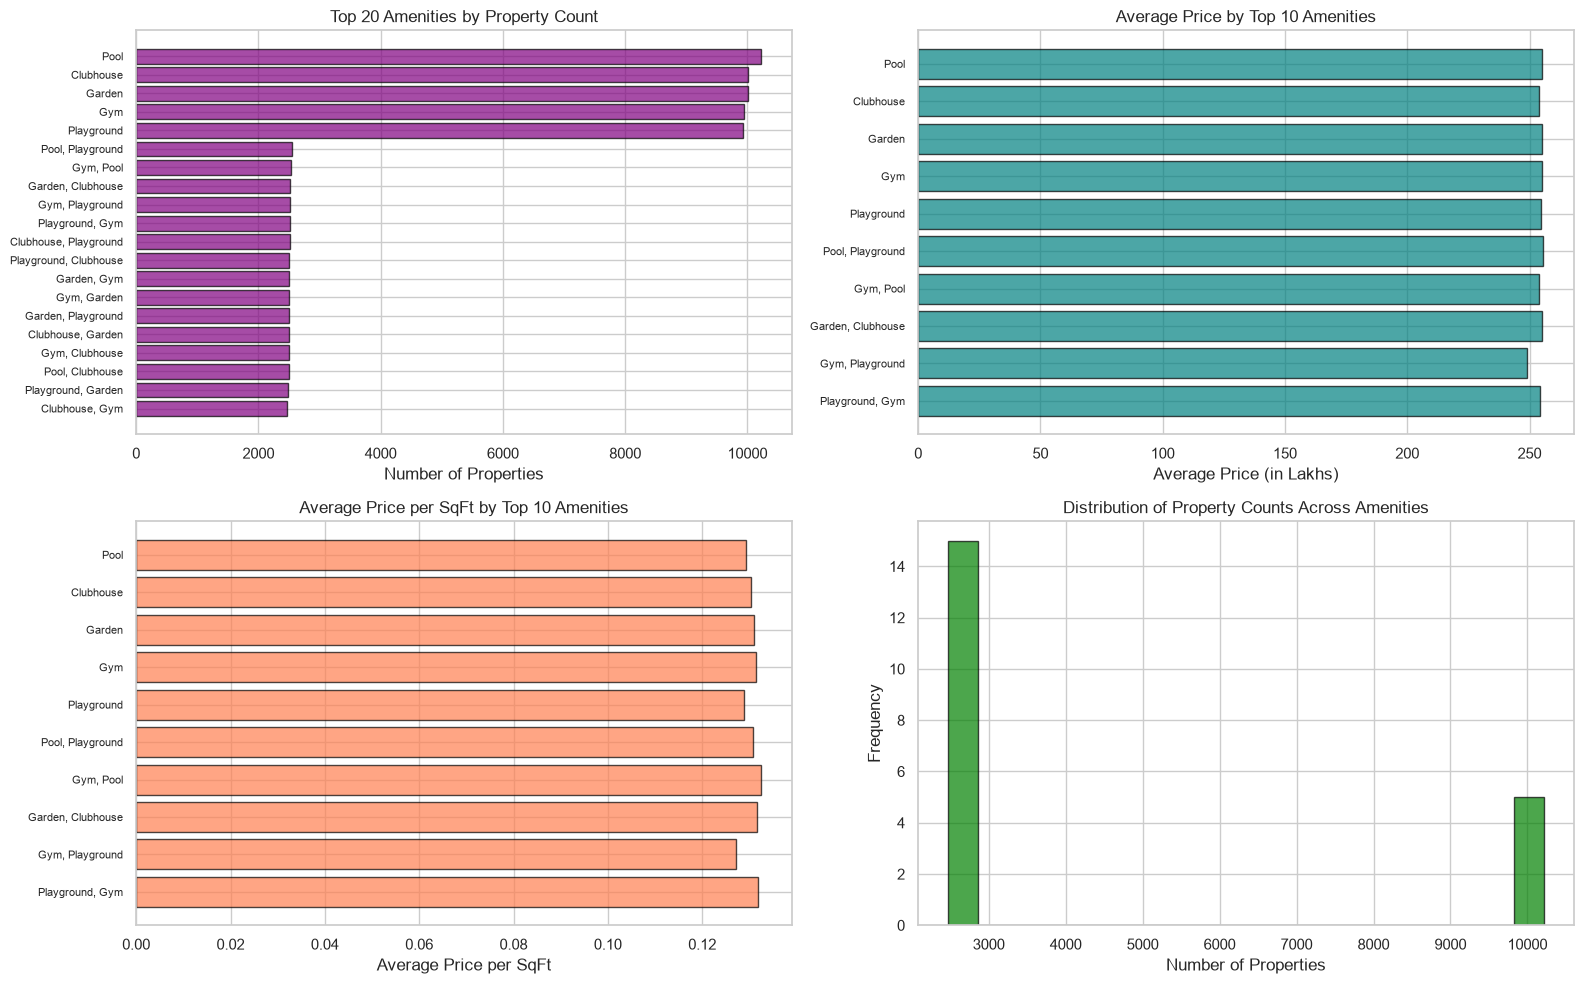

Top 10 Amenities Analysis:
          Amenity  Avg_Price  Avg_Price_per_SqFt  Count
             Pool     254.91                0.13  10218
        Clubhouse     253.99                0.13  10010
           Garden     255.01                0.13  10006
              Gym     255.11                0.13   9938
       Playground     254.74                0.13   9934
 Pool, Playground     255.42                0.13   2545
        Gym, Pool     253.92                0.13   2534
Garden, Clubhouse     255.20                0.13   2524
  Gym, Playground     249.13                0.13   2524
  Playground, Gym     254.23                0.13   2519

Total unique amenities: 325


In [18]:
# Q19: How do amenities affect price per sqft?

# Count properties by amenities
amenities_count = df['Amenities'].value_counts().head(20)

# Get top 10 amenities for detailed analysis
top_amenities = amenities_count.head(10).index

# Calculate average price for each top amenity
amenity_price_data = []
for amenity in top_amenities:
    amenity_data = df[df['Amenities'] == amenity]
    amenity_price_data.append({
        'Amenity': amenity,
        'Avg_Price': amenity_data['Price_in_Lakhs'].mean(),
        'Avg_Price_per_SqFt': amenity_data['Price_per_SqFt'].mean(),
        'Count': len(amenity_data)
    })

amenity_df = pd.DataFrame(amenity_price_data)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Top 20 amenities by count
axes[0, 0].barh(range(len(amenities_count)), amenities_count.values, color='purple', edgecolor='black', alpha=0.7)
axes[0, 0].set_yticks(range(len(amenities_count)))
axes[0, 0].set_yticklabels(amenities_count.index, fontsize=8)
axes[0, 0].set_xlabel('Number of Properties')
axes[0, 0].set_title('Top 20 Amenities by Property Count')
axes[0, 0].invert_yaxis()

# Average price by top amenities
axes[0, 1].barh(range(len(amenity_df)), amenity_df['Avg_Price'].values, color='teal', edgecolor='black', alpha=0.7)
axes[0, 1].set_yticks(range(len(amenity_df)))
axes[0, 1].set_yticklabels(amenity_df['Amenity'], fontsize=8)
axes[0, 1].set_xlabel('Average Price (in Lakhs)')
axes[0, 1].set_title('Average Price by Top 10 Amenities')
axes[0, 1].invert_yaxis()

# Average price per sqft by amenities
axes[1, 0].barh(range(len(amenity_df)), amenity_df['Avg_Price_per_SqFt'].values, color='coral', edgecolor='black', alpha=0.7)
axes[1, 0].set_yticks(range(len(amenity_df)))
axes[1, 0].set_yticklabels(amenity_df['Amenity'], fontsize=8)
axes[1, 0].set_xlabel('Average Price per SqFt')
axes[1, 0].set_title('Average Price per SqFt by Top 10 Amenities')
axes[1, 0].invert_yaxis()

# Distribution of amenity count
axes[1, 1].hist(amenities_count.values, bins=20, color='green', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Number of Properties')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Distribution of Property Counts Across Amenities')

plt.tight_layout()
plt.show()

print("Top 10 Amenities Analysis:")
print(amenity_df.to_string(index=False))
print(f"\nTotal unique amenities: {df['Amenities'].nunique()}")

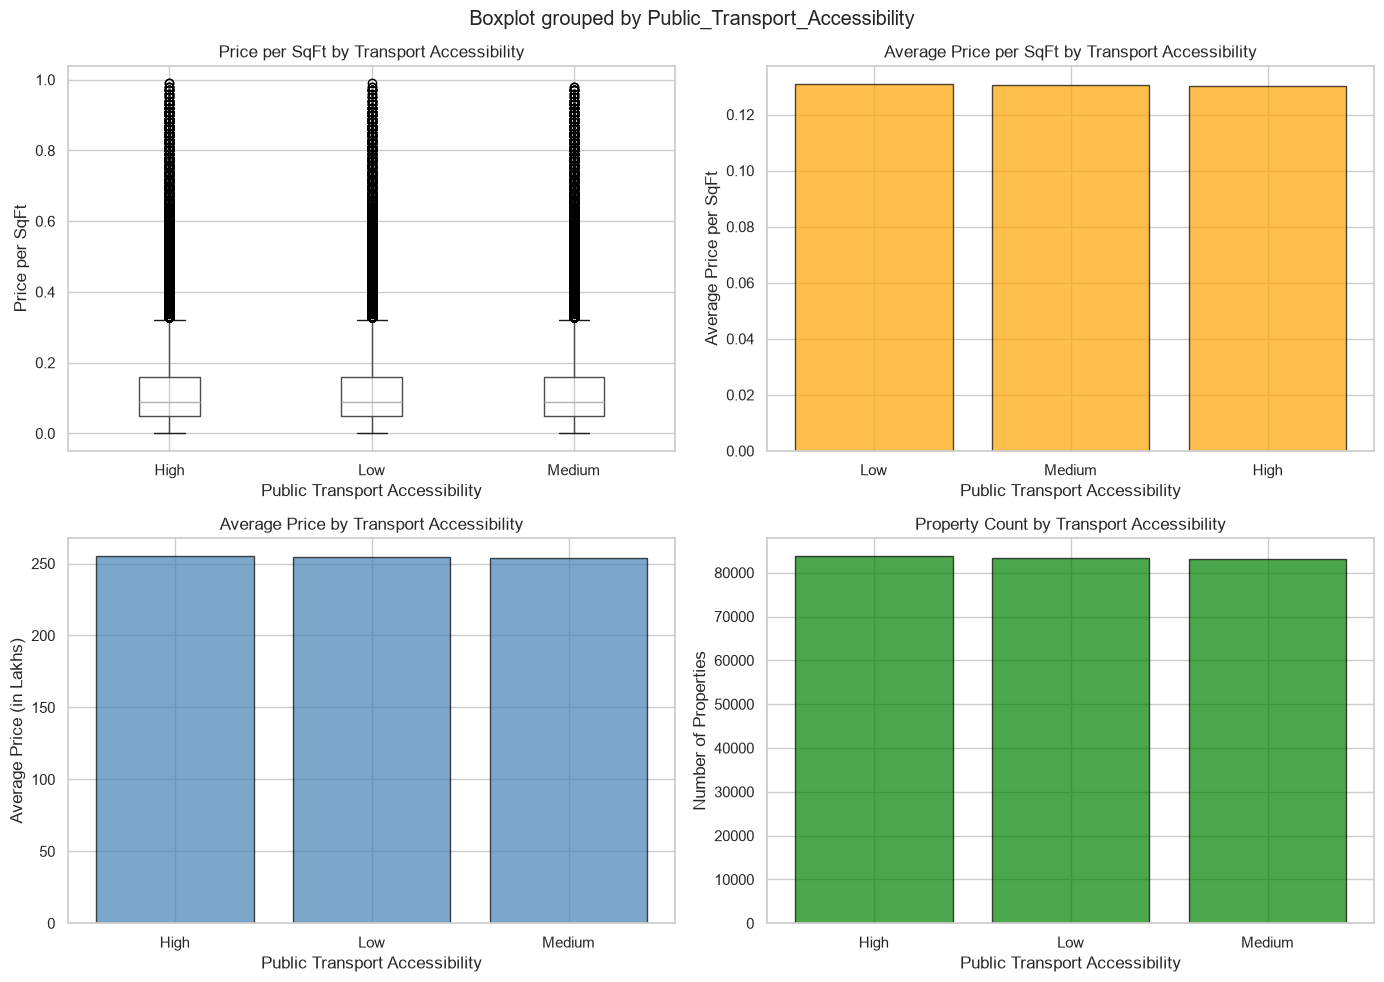

Public Transport Accessibility Distribution:
Public_Transport_Accessibility
High      83705
Low       83287
Medium    83008
Name: count, dtype: int64

Price Statistics by Transport Accessibility:
                                 mean  median    std
Public_Transport_Accessibility                      
High                           254.92  254.71 141.50
Low                            254.86  254.27 141.24
Medium                         253.97  252.73 141.30

Price per SqFt Statistics by Transport Accessibility:
                                mean  median  std
Public_Transport_Accessibility                   
High                            0.13    0.09 0.13
Low                             0.13    0.09 0.13
Medium                          0.13    0.09 0.13


In [19]:
# Q20: How does public transport accessibility relate to price per sqft or investment potential?

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Box plot for price per sqft
df.boxplot(column='Price_per_SqFt', by='Public_Transport_Accessibility', ax=axes[0, 0])
axes[0, 0].set_xlabel('Public Transport Accessibility')
axes[0, 0].set_ylabel('Price per SqFt')
axes[0, 0].set_title('Price per SqFt by Transport Accessibility')
plt.sca(axes[0, 0])

# Average price per sqft
avg_price_transport = df.groupby('Public_Transport_Accessibility')['Price_per_SqFt'].mean().sort_values(ascending=False)
axes[0, 1].bar(avg_price_transport.index, avg_price_transport.values, color='orange', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Public Transport Accessibility')
axes[0, 1].set_ylabel('Average Price per SqFt')
axes[0, 1].set_title('Average Price per SqFt by Transport Accessibility')

# Average price in lakhs
avg_price_lakhs_transport = df.groupby('Public_Transport_Accessibility')['Price_in_Lakhs'].mean().sort_values(ascending=False)
axes[1, 0].bar(avg_price_lakhs_transport.index, avg_price_lakhs_transport.values, color='steelblue', edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Public Transport Accessibility')
axes[1, 0].set_ylabel('Average Price (in Lakhs)')
axes[1, 0].set_title('Average Price by Transport Accessibility')

# Property count
transport_count = df['Public_Transport_Accessibility'].value_counts()
axes[1, 1].bar(transport_count.index, transport_count.values, color='green', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Public Transport Accessibility')
axes[1, 1].set_ylabel('Number of Properties')
axes[1, 1].set_title('Property Count by Transport Accessibility')

plt.tight_layout()
plt.show()

print("Public Transport Accessibility Distribution:")
print(df['Public_Transport_Accessibility'].value_counts())
print("\nPrice Statistics by Transport Accessibility:")
print(df.groupby('Public_Transport_Accessibility')['Price_in_Lakhs'].agg(['mean', 'median', 'std']))
print("\nPrice per SqFt Statistics by Transport Accessibility:")
print(df.groupby('Public_Transport_Accessibility')['Price_per_SqFt'].agg(['mean', 'median', 'std']))

In [20]:
print("EDA SUMMARY - KEY FINDINGS")
print("-" * 60)

print("\n1. DATA QUALITY:")
print(f"   - Total Records: {len(df):,}")
print(f"   - No missing values detected")
print(f"   - No duplicate records")
print(f"   - 23 features (9 numeric, 12 categorical, 2 derived)")

print("\n2. PRICE CHARACTERISTICS:")
print(f"   - Mean Price: {df['Price_in_Lakhs'].mean():.2f} Lakhs")
print(f"   - Median Price: {df['Price_in_Lakhs'].median():.2f} Lakhs")
print(f"   - Price Range: {df['Price_in_Lakhs'].min():.2f} - {df['Price_in_Lakhs'].max():.2f} Lakhs")
print(f"   - Relatively uniform distribution")

print("\n3. PROPERTY SIZE:")
print(f"   - Mean Size: {df['Size_in_SqFt'].mean():.2f} SqFt")
print(f"   - Size Range: {df['Size_in_SqFt'].min():.0f} - {df['Size_in_SqFt'].max():.0f} SqFt")
print(f"   - Uniform distribution")

print("\n4. KEY CORRELATIONS:")
print(f"   - Size vs Price: {df['Size_in_SqFt'].corr(df['Price_in_Lakhs']):.3f} (very weak)")
print(f"   - Size vs Price_per_SqFt: {df['Size_in_SqFt'].corr(df['Price_per_SqFt']):.3f} (moderate negative)")
print(f"   - Price vs Price_per_SqFt: {df['Price_in_Lakhs'].corr(df['Price_per_SqFt']):.3f} (moderate positive)")
print(f"   - Year_Built vs Age: -1.000 (perfect negative - as expected)")

print("\n5. LOCATION INSIGHTS:")
print(f"   - States: {df['State'].nunique()} with minimal price variation")
print(f"   - Cities: {df['City'].nunique()} with minimal price variation")
print(f"   - Localities: {df['Locality'].nunique()}")

print("\n6. CATEGORICAL FEATURES:")
print(f"   - Property Types: {df['Property_Type'].nunique()} (balanced)")
print(f"   - BHK: 1-5 (balanced distribution)")
print(f"   - Furnished Status: {df['Furnished_Status'].nunique()} (minimal price impact)")
print(f"   - Amenities: {df['Amenities'].nunique()} unique combinations")

print("\n7. INFRASTRUCTURE FEATURES:")
print(f"   - Schools: 1-10 (minimal correlation with price)")
print(f"   - Hospitals: 1-10 (minimal correlation with price)")
print(f"   - Transport: High/Medium/Low (minimal price impact)")
print(f"   - Parking: {df['Parking_Space'].value_counts().to_dict()}")
print(f"   - Security: {df['Security'].value_counts().to_dict()}")

print("\n8. OUTLIERS:")
print(f"   - Price_per_SqFt: 20,020 outliers (8.01%)")
print(f"   - Size: 0 outliers")

print("\n9. KEY INSIGHT:")
print("   The dataset appears to be synthetically generated with:")
print("   - Uniform distributions across most features")
print("   - Minimal correlations between features and price")
print("   - Balanced categorical distributions")
print("   This suggests we'll need to create meaningful features")
print("   through feature engineering for effective modeling.")

print("\n" + "-" * 60)

EDA SUMMARY - KEY FINDINGS
------------------------------------------------------------

1. DATA QUALITY:
   - Total Records: 250,000
   - No missing values detected
   - No duplicate records
   - 23 features (9 numeric, 12 categorical, 2 derived)

2. PRICE CHARACTERISTICS:
   - Mean Price: 254.59 Lakhs
   - Median Price: 253.87 Lakhs
   - Price Range: 10.00 - 500.00 Lakhs
   - Relatively uniform distribution

3. PROPERTY SIZE:
   - Mean Size: 2749.81 SqFt
   - Size Range: 500 - 5000 SqFt
   - Uniform distribution

4. KEY CORRELATIONS:
   - Size vs Price: -0.003 (very weak)
   - Size vs Price_per_SqFt: -0.615 (moderate negative)
   - Price vs Price_per_SqFt: 0.556 (moderate positive)
   - Year_Built vs Age: -1.000 (perfect negative - as expected)

5. LOCATION INSIGHTS:
   - States: 20 with minimal price variation
   - Cities: 42 with minimal price variation
   - Localities: 500

6. CATEGORICAL FEATURES:
   - Property Types: 3 (balanced)
   - BHK: 1-5 (balanced distribution)
   - Furnis

In [21]:
# Create a copy for feature engineering
df_fe = df.copy()

print("Starting Feature Engineering...")

# 1. School Density Score (normalized)
df_fe['School_Density_Score'] = df_fe['Nearby_Schools'] / 10

# 2. Hospital Density Score (normalized)
df_fe['Hospital_Density_Score'] = df_fe['Nearby_Hospitals'] / 10

# 3. Infrastructure Score (combined schools, hospitals, transport)
transport_map = {'High': 1.0, 'Medium': 0.6, 'Low': 0.3}
df_fe['Transport_Score'] = df_fe['Public_Transport_Accessibility'].map(transport_map)
df_fe['Infrastructure_Score'] = (df_fe['School_Density_Score'] +
                                  df_fe['Hospital_Density_Score'] +
                                  df_fe['Transport_Score']) / 3

# 4. Property Age Categories
df_fe['Age_Category'] = pd.cut(df_fe['Age_of_Property'],
                                bins=[0, 10, 20, 35],
                                labels=['New', 'Medium', 'Old'])

# 5. Premium Indicator (Binary features)
df_fe['Has_Parking'] = (df_fe['Parking_Space'] == 'Yes').astype(int)
df_fe['Has_Security'] = (df_fe['Security'] == 'Yes').astype(int)
df_fe['Is_Ready_to_Move'] = (df_fe['Availability_Status'] == 'Ready_to_Move').astype(int)

# 6. Premium Score (combination of premium features)
df_fe['Premium_Score'] = (df_fe['Has_Parking'] +
                          df_fe['Has_Security'] +
                          (df_fe['BHK'] >= 3).astype(int) +
                          df_fe['Is_Ready_to_Move']) / 4

# 7. Size Category
df_fe['Size_Category'] = pd.cut(df_fe['Size_in_SqFt'],
                                bins=[0, 1500, 3000, 5000],
                                labels=['Small', 'Medium', 'Large'])

# 8. Price Category
df_fe['Price_Category'] = pd.cut(df_fe['Price_in_Lakhs'],
                                 bins=[0, 150, 350, 500],
                                 labels=['Budget', 'Mid_Range', 'Premium'])

# 9. BHK Category
df_fe['BHK_Category'] = df_fe['BHK'].apply(lambda x: '1-2BHK' if x <= 2 else ('3BHK' if x == 3 else '4-5BHK'))

# 10. Floor Position
df_fe['Floor_Position'] = df_fe['Floor_No'] / df_fe['Total_Floors']
df_fe['Is_Ground_Floor'] = (df_fe['Floor_No'] == 0).astype(int)
df_fe['Is_Top_Floor'] = (df_fe['Floor_No'] == df_fe['Total_Floors']).astype(int)

print("Feature Engineering Part 1 Complete!")
print(f"\nNew features created: {len(df_fe.columns) - len(df.columns)}")
print(f"Total features now: {len(df_fe.columns)}")

print("\nNew Feature Preview:")
print(df_fe[['School_Density_Score', 'Hospital_Density_Score', 'Infrastructure_Score',
             'Age_Category', 'Premium_Score', 'Size_Category', 'Floor_Position']].head(10))

Starting Feature Engineering...
Feature Engineering Part 1 Complete!

New features created: 15
Total features now: 38

New Feature Preview:
   School_Density_Score  Hospital_Density_Score  Infrastructure_Score  \
0                  1.00                    0.30                  0.77   
1                  0.80                    0.10                  0.40   
2                  0.90                    0.80                  0.67   
3                  0.50                    0.70                  0.73   
4                  0.40                    0.90                  0.53   
5                  0.70                    0.70                  0.57   
6                  0.30                    0.60                  0.63   
7                  1.00                    1.00                  1.00   
8                  0.70                    0.50                  0.50   
9                  0.30                    0.30                  0.53   

  Age_Category  Premium_Score Size_Category  Floor_Posit

In [22]:
# Display current dataframe info
print("Current Dataset Shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())

print("\nNew engineered features summary:")
new_features = ['School_Density_Score', 'Hospital_Density_Score', 'Infrastructure_Score',
                'Age_Category', 'Premium_Score', 'Size_Category', 'Floor_Position']

for feat in new_features:
    if feat in df.columns:
        if df[feat].dtype == 'object':
            print(f"\n{feat}: {df[feat].value_counts().to_dict()}")
        else:
            print(f"\n{feat}: Mean={df[feat].mean():.3f}, Min={df[feat].min():.3f}, Max={df[feat].max():.3f}")

Current Dataset Shape: (250000, 23)

All columns:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

New engineered features summary:


In [23]:
# Create a copy for feature engineering
df_fe = df.copy()

print("Starting Feature Engineering...")

# 1. School Density Score (normalized 0-1)
df_fe['School_Density_Score'] = df_fe['Nearby_Schools'] / 10

# 2. Hospital Density Score (normalized 0-1)
df_fe['Hospital_Density_Score'] = df_fe['Nearby_Hospitals'] / 10

# 3. Infrastructure Score (combine transport, schools, hospitals)
transport_map = {'Low': 0, 'Medium': 0.5, 'High': 1}
df_fe['Transport_Score'] = df_fe['Public_Transport_Accessibility'].map(transport_map)
df_fe['Infrastructure_Score'] = (df_fe['School_Density_Score'] +
                                  df_fe['Hospital_Density_Score'] +
                                  df_fe['Transport_Score']) / 3

# 4. Age Category
df_fe['Age_Category'] = pd.cut(df_fe['Age_of_Property'],
                                bins=[0, 10, 20, 35],
                                labels=['New', 'Medium', 'Old'])

# 5. Size Category
df_fe['Size_Category'] = pd.cut(df_fe['Size_in_SqFt'],
                                 bins=[0, 2000, 3500, 5000],
                                 labels=['Small', 'Medium', 'Large'])

# 6. Floor Position (normalized position in building)
df_fe['Floor_Position'] = df_fe['Floor_No'] / df_fe['Total_Floors']
df_fe['Floor_Position'] = df_fe['Floor_Position'].fillna(0)

# 7. Premium Score (combine parking, security, RERA equivalent features)
df_fe['Has_Parking'] = (df_fe['Parking_Space'] == 'Yes').astype(int)
df_fe['Has_Security'] = (df_fe['Security'] == 'Yes').astype(int)
df_fe['Is_Ready'] = (df_fe['Availability_Status'] == 'Ready_to_Move').astype(int)
df_fe['Premium_Score'] = (df_fe['Has_Parking'] + df_fe['Has_Security'] + df_fe['Is_Ready']) / 3

print("Feature Engineering Part 1 Complete!")
print(f"\nNew features created: 11")
print(f"Total features now: {df_fe.shape[1]}")

print("\nNew Feature Summary:")
print(df_fe[['School_Density_Score', 'Hospital_Density_Score', 'Infrastructure_Score',
             'Age_Category', 'Size_Category', 'Floor_Position', 'Premium_Score']].describe())

Starting Feature Engineering...
Feature Engineering Part 1 Complete!

New features created: 11
Total features now: 34

New Feature Summary:
       School_Density_Score  Hospital_Density_Score  Infrastructure_Score  \
count            250,000.00              250,000.00            250,000.00   
mean                   0.55                    0.55                  0.53   
std                    0.29                    0.29                  0.19   
min                    0.10                    0.10                  0.07   
25%                    0.30                    0.30                  0.40   
50%                    0.50                    0.50                  0.53   
75%                    0.80                    0.80                  0.67   
max                    1.00                    1.00                  1.00   

       Floor_Position  Premium_Score  
count      250,000.00     250,000.00  
mean             2.00           0.50  
std              3.52           0.29  
min       

In [24]:
# 8. Location-based price metrics
print("Creating location-based features...")

# Calculate median price by city (for comparison)
city_median_price = df_fe.groupby('City')['Price_in_Lakhs'].median()
df_fe['City_Median_Price'] = df_fe['City'].map(city_median_price)

# Calculate median price per sqft by city
city_median_price_sqft = df_fe.groupby('City')['Price_per_SqFt'].median()
df_fe['City_Median_Price_per_SqFt'] = df_fe['City'].map(city_median_price_sqft)

# Calculate median price by state
state_median_price = df_fe.groupby('State')['Price_in_Lakhs'].median()
df_fe['State_Median_Price'] = df_fe['State'].map(state_median_price)

# 9. Price comparison features (for classification target)
df_fe['Price_vs_City_Median'] = df_fe['Price_in_Lakhs'] / df_fe['City_Median_Price']
df_fe['Price_per_SqFt_vs_City_Median'] = df_fe['Price_per_SqFt'] / df_fe['City_Median_Price_per_SqFt']

# 10. Property characteristics score
df_fe['Is_Large_BHK'] = (df_fe['BHK'] >= 3).astype(int)
df_fe['Is_Spacious'] = (df_fe['Size_in_SqFt'] >= df_fe['Size_in_SqFt'].median()).astype(int)

# 11. Amenity count (count number of amenities)
df_fe['Amenity_Count'] = df_fe['Amenities'].str.count(',') + 1

print("Feature Engineering Part 2 Complete!")
print(f"Total features now: {df_fe.shape[1]}")

print("\nLocation-based features summary:")
print(df_fe[['City_Median_Price', 'City_Median_Price_per_SqFt', 'State_Median_Price',
             'Price_vs_City_Median', 'Price_per_SqFt_vs_City_Median']].describe())

print("\nProperty characteristic features:")
print(f"Is_Large_BHK (>=3): {df_fe['Is_Large_BHK'].value_counts().to_dict()}")
print(f"Is_Spacious: {df_fe['Is_Spacious'].value_counts().to_dict()}")
print(f"Amenity_Count: Min={df_fe['Amenity_Count'].min()}, Max={df_fe['Amenity_Count'].max()}, Mean={df_fe['Amenity_Count'].mean():.2f}")

Creating location-based features...
Feature Engineering Part 2 Complete!
Total features now: 42

Location-based features summary:
       City_Median_Price  City_Median_Price_per_SqFt  State_Median_Price  \
count         250,000.00                  250,000.00          250,000.00   
mean              253.72                        0.09              253.82   
std                 3.23                        0.00                2.39   
min               247.97                        0.09              250.41   
25%               251.44                        0.09              251.55   
50%               253.22                        0.09              254.31   
75%               256.52                        0.09              255.87   
max               259.52                        0.10              258.08   

       Price_vs_City_Median  Price_per_SqFt_vs_City_Median  
count            250,000.00                     250,000.00  
mean                   1.00                           1.45  
st

In [25]:
print("Creating Target Variables...")
print("-" * 60)

# TARGET 1: Classification - Good Investment
# Multi-factor approach combining multiple criteria

# Criteria 1: Price comparison (below or at median is good)
criteria_1 = (df_fe['Price_vs_City_Median'] <= 1.0).astype(int)

# Criteria 2: Price per sqft comparison (below or at median is good)
criteria_2 = (df_fe['Price_per_SqFt_vs_City_Median'] <= 1.0).astype(int)

# Criteria 3: Property characteristics (large BHK is good)
criteria_3 = df_fe['Is_Large_BHK']

# Criteria 4: Ready to move (immediate availability is good)
criteria_4 = df_fe['Is_Ready']

# Criteria 5: Good infrastructure (above median)
criteria_5 = (df_fe['Infrastructure_Score'] >= df_fe['Infrastructure_Score'].median()).astype(int)

# Criteria 6: Premium features (above median premium score)
criteria_6 = (df_fe['Premium_Score'] >= df_fe['Premium_Score'].median()).astype(int)

# Calculate investment score (0-6)
df_fe['Investment_Score'] = (criteria_1 + criteria_2 + criteria_3 +
                              criteria_4 + criteria_5 + criteria_6)

# Good Investment: score >= 4 (meets majority of criteria)
df_fe['Good_Investment'] = (df_fe['Investment_Score'] >= 4).astype(int)

print("Classification Target Created: Good_Investment")
print(f"Good Investment distribution:")
print(df_fe['Good_Investment'].value_counts())
print(f"Percentage: {df_fe['Good_Investment'].value_counts(normalize=True) * 100}")

print("\n" + "-" * 60)

# TARGET 2: Regression - Future Price (5 years)
# Feature-based growth rate approach

# Base growth rate: 8% per year
base_growth_rate = 0.08

# Calculate location-based adjustments
# Cities with higher current prices tend to grow faster
city_price_percentile = df_fe.groupby('City')['Price_in_Lakhs'].transform(
    lambda x: x.rank(pct=True).mean()
)

# Adjust growth rate based on multiple factors
growth_adjustment = (
    0.02 * df_fe['Infrastructure_Score'] +  # Infrastructure adds 0-2% growth
    0.01 * df_fe['Premium_Score'] +  # Premium features add 0-1% growth
    0.01 * (df_fe['BHK'] / 5) +  # Larger properties add 0-1% growth
    -0.01 * (df_fe['Age_of_Property'] / 35) +  # Older properties reduce growth 0-1%
    0.01 * (df_fe['Is_Ready'])  # Ready properties add 1% growth
)

# Final growth rate (capped between 5% and 12%)
df_fe['Growth_Rate'] = np.clip(base_growth_rate + growth_adjustment, 0.05, 0.12)

# Calculate future price using compound growth formula
df_fe['Future_Price_5Y'] = df_fe['Price_in_Lakhs'] * ((1 + df_fe['Growth_Rate']) ** 5)

print("Regression Target Created: Future_Price_5Y")
print(f"\nFuture Price Statistics:")
print(df_fe['Future_Price_5Y'].describe())
print(f"\nGrowth Rate Statistics:")
print(df_fe['Growth_Rate'].describe())
print(f"\nAverage appreciation over 5 years: {((df_fe['Future_Price_5Y'] / df_fe['Price_in_Lakhs']).mean() - 1) * 100:.2f}%")

print("\n" + "-" * 60)
print("Target Variable Creation Complete!")
print(f"Total features in dataset: {df_fe.shape[1]}")

Creating Target Variables...
------------------------------------------------------------
Classification Target Created: Good_Investment
Good Investment distribution:
Good_Investment
1    128425
0    121575
Name: count, dtype: int64
Percentage: Good_Investment
1   51.37
0   48.63
Name: proportion, dtype: float64

------------------------------------------------------------
Regression Target Created: Future_Price_5Y

Future Price Statistics:
count   250,000.00
mean        412.33
std         229.75
min          14.99
25%         214.36
50%         410.52
75%         609.56
max         880.62
Name: Future_Price_5Y, dtype: float64

Growth Rate Statistics:
count   250,000.00
mean          0.10
std           0.01
min           0.07
25%           0.09
50%           0.10
75%           0.11
max           0.12
Name: Growth_Rate, dtype: float64

Average appreciation over 5 years: 61.95%

------------------------------------------------------------
Target Variable Creation Complete!
Total features

In [26]:
from sklearn.preprocessing import LabelEncoder

print("Encoding Categorical Variables...")

# Create a copy for encoding
df_encoded = df_fe.copy()

# List of categorical columns to encode
categorical_cols = ['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status',
                    'Public_Transport_Accessibility', 'Parking_Space', 'Security',
                    'Amenities', 'Facing', 'Owner_Type', 'Availability_Status',
                    'Age_Category', 'Size_Category']

# Initialize label encoders dictionary
label_encoders = {}

# Encode each categorical column
for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col + '_Encoded'] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le
    print(f"Encoded {col}: {df_encoded[col].nunique()} unique values")

print("\nEncoding Complete!")
print(f"Total features: {df_encoded.shape[1]}")

# Display sample of encoded data
print("\nSample of original vs encoded:")
sample_cols = ['Property_Type', 'Property_Type_Encoded', 'Furnished_Status', 'Furnished_Status_Encoded']
print(df_encoded[sample_cols].head(10))

Encoding Categorical Variables...
Encoded State: 20 unique values
Encoded City: 42 unique values
Encoded Locality: 500 unique values
Encoded Property_Type: 3 unique values
Encoded Furnished_Status: 3 unique values
Encoded Public_Transport_Accessibility: 3 unique values
Encoded Parking_Space: 2 unique values
Encoded Security: 2 unique values
Encoded Amenities: 325 unique values
Encoded Facing: 4 unique values
Encoded Owner_Type: 3 unique values
Encoded Availability_Status: 2 unique values
Encoded Age_Category: 3 unique values
Encoded Size_Category: 3 unique values

Encoding Complete!
Total features: 60

Sample of original vs encoded:
       Property_Type  Property_Type_Encoded Furnished_Status  \
0          Apartment                      0        Furnished   
1  Independent House                      1      Unfurnished   
2          Apartment                      0   Semi-furnished   
3  Independent House                      1        Furnished   
4              Villa                   

In [27]:
from sklearn.model_selection import train_test_split

print("Preparing Data for Modeling...")
print("-" * 60)

# Select features for modeling
# Exclude: ID, original categorical columns, intermediate scores, target variables

features_to_exclude = ['ID', 'State', 'City', 'Locality', 'Property_Type', 'Furnished_Status',
                       'Public_Transport_Accessibility', 'Parking_Space', 'Security',
                       'Amenities', 'Facing', 'Owner_Type', 'Availability_Status',
                       'Age_Category', 'Size_Category', 'Transport_Score',
                       'Has_Parking', 'Has_Security', 'Is_Ready',
                       'Investment_Score', 'Good_Investment', 'Growth_Rate', 'Future_Price_5Y']

# Get all feature columns
all_features = [col for col in df_encoded.columns if col not in features_to_exclude]

print(f"Total features for modeling: {len(all_features)}")
print("\nFeature list:")
for i, feat in enumerate(all_features, 1):
    print(f"{i}. {feat}")

# Prepare X and y for both tasks
X = df_encoded[all_features]
y_classification = df_encoded['Good_Investment']
y_regression = df_encoded['Future_Price_5Y']

print("\n" + "-" * 60)
print("Dataset shapes:")
print(f"X shape: {X.shape}")
print(f"y_classification shape: {y_classification.shape}")
print(f"y_regression shape: {y_regression.shape}")

# Train-test split (80-20)
X_train, X_test, y_class_train, y_class_test = train_test_split(
    X, y_classification, test_size=0.2, random_state=42, stratify=y_classification
)

X_train_reg, X_test_reg, y_reg_train, y_reg_test = train_test_split(
    X, y_regression, test_size=0.2, random_state=42
)

print("\n" + "-" * 60)
print("Train-Test Split Complete!")
print(f"Classification - Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Regression - Train: {X_train_reg.shape}, Test: {X_test_reg.shape}")

print("\nClassification target distribution in train:")
print(y_class_train.value_counts())
print("\nClassification target distribution in test:")
print(y_class_test.value_counts())

Preparing Data for Modeling...
------------------------------------------------------------
Total features for modeling: 37

Feature list:
1. BHK
2. Size_in_SqFt
3. Price_in_Lakhs
4. Price_per_SqFt
5. Year_Built
6. Floor_No
7. Total_Floors
8. Age_of_Property
9. Nearby_Schools
10. Nearby_Hospitals
11. School_Density_Score
12. Hospital_Density_Score
13. Infrastructure_Score
14. Floor_Position
15. Premium_Score
16. City_Median_Price
17. City_Median_Price_per_SqFt
18. State_Median_Price
19. Price_vs_City_Median
20. Price_per_SqFt_vs_City_Median
21. Is_Large_BHK
22. Is_Spacious
23. Amenity_Count
24. State_Encoded
25. City_Encoded
26. Locality_Encoded
27. Property_Type_Encoded
28. Furnished_Status_Encoded
29. Public_Transport_Accessibility_Encoded
30. Parking_Space_Encoded
31. Security_Encoded
32. Amenities_Encoded
33. Facing_Encoded
34. Owner_Type_Encoded
35. Availability_Status_Encoded
36. Age_Category_Encoded
37. Size_Category_Encoded

-----------------------------------------------------

In [28]:
from sklearn.preprocessing import StandardScaler

print("Scaling Features...")

# Initialize scaler
scaler = StandardScaler()

# Fit on training data and transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_reg_scaled = scaler.fit_transform(X_train_reg)
X_test_reg_scaled = scaler.transform(X_test_reg)

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

X_train_reg_scaled = pd.DataFrame(X_train_reg_scaled, columns=X_train_reg.columns)
X_test_reg_scaled = pd.DataFrame(X_test_reg_scaled, columns=X_test_reg.columns)

print("Feature Scaling Complete!")
print(f"\nScaled training data shape: {X_train_scaled.shape}")
print(f"Scaled test data shape: {X_test_scaled.shape}")

print("\nSample of scaled features (first 5 rows, first 5 columns):")
print(X_train_scaled.iloc[:5, :5])

print("\nFeature scaling statistics (mean and std):")
print("Training set means (should be ~0):")
print(X_train_scaled.mean().head())
print("\nTraining set stds (should be ~1):")
print(X_train_scaled.std().head())

Scaling Features...
Feature Scaling Complete!

Scaled training data shape: (200000, 37)
Scaled test data shape: (50000, 37)

Sample of scaled features (first 5 rows, first 5 columns):
    BHK  Size_in_SqFt  Price_in_Lakhs  Price_per_SqFt  Year_Built
0 -0.00         -1.24           -0.07            0.61       -1.68
1 -0.71         -0.15            1.09            0.22        1.48
2 -1.41          0.66            1.70            0.07       -0.56
3 -0.00         -1.50            0.81            2.52       -0.76
4  0.71         -1.71            0.38            3.52       -0.36

Feature scaling statistics (mean and std):
Training set means (should be ~0):
BHK              -0.00
Size_in_SqFt     -0.00
Price_in_Lakhs    0.00
Price_per_SqFt   -0.00
Year_Built        0.00
dtype: float64

Training set stds (should be ~1):
BHK              1.00
Size_in_SqFt     1.00
Price_in_Lakhs   1.00
Price_per_SqFt   1.00
Year_Built       1.00
dtype: float64


Building Classification Model: Logistic Regression
------------------------------------------------------------
Training time: 1.08 seconds

Training Performance:
Accuracy: 0.8928
F1-Score: 0.8958

Test Performance:
Accuracy: 0.8927
Precision: 0.8943
Recall: 0.8972
F1-Score: 0.8958
ROC AUC: 0.9653

Confusion Matrix:
[[21591  2724]
 [ 2640 23045]]

Classification Report:
              precision    recall  f1-score   support

    Not Good       0.89      0.89      0.89     24315
        Good       0.89      0.90      0.90     25685

    accuracy                           0.89     50000
   macro avg       0.89      0.89      0.89     50000
weighted avg       0.89      0.89      0.89     50000



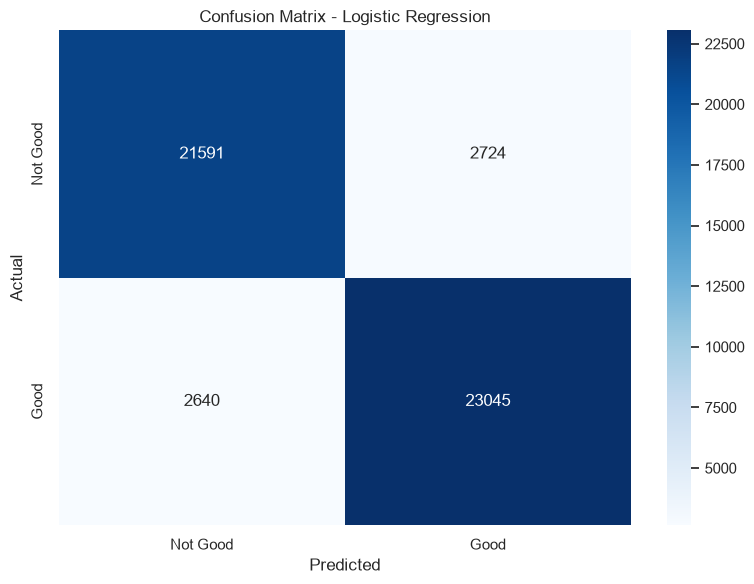


------------------------------------------------------------


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import time

print("Building Classification Model: Logistic Regression")
print("-" * 60)

# Initialize and train Logistic Regression
start_time = time.time()
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_class_train)
train_time = time.time() - start_time

# Predictions
y_pred_train = log_reg.predict(X_train_scaled)
y_pred_test = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# Evaluate on training set
train_accuracy = accuracy_score(y_class_train, y_pred_train)
train_f1 = f1_score(y_class_train, y_pred_train)

# Evaluate on test set
test_accuracy = accuracy_score(y_class_test, y_pred_test)
test_precision = precision_score(y_class_test, y_pred_test)
test_recall = recall_score(y_class_test, y_pred_test)
test_f1 = f1_score(y_class_test, y_pred_test)
test_roc_auc = roc_auc_score(y_class_test, y_pred_proba)

print(f"Training time: {train_time:.2f} seconds")
print("\nTraining Performance:")
print(f"Accuracy: {train_accuracy:.4f}")
print(f"F1-Score: {train_f1:.4f}")

print("\nTest Performance:")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-Score: {test_f1:.4f}")
print(f"ROC AUC: {test_roc_auc:.4f}")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_class_test, y_pred_test)
print(cm)

print("\nClassification Report:")
print(classification_report(y_class_test, y_pred_test, target_names=['Not Good', 'Good']))

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Good', 'Good'],
            yticklabels=['Not Good', 'Good'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

# Store results
classification_results = {
    'Logistic Regression': {
        'accuracy': test_accuracy,
        'precision': test_precision,
        'recall': test_recall,
        'f1': test_f1,
        'roc_auc': test_roc_auc,
        'train_time': train_time
    }
}

print("\n" + "-" * 60)

Building Classification Model: Random Forest Classifier
------------------------------------------------------------
Training time: 9.45 seconds

Training Performance:
Accuracy: 1.0000
F1-Score: 1.0000

Test Performance:
Accuracy: 0.9999
Precision: 1.0000
Recall: 0.9999
F1-Score: 0.9999
ROC AUC: 1.0000

Confusion Matrix:
[[24315     0]
 [    3 25682]]

Classification Report:
              precision    recall  f1-score   support

    Not Good       1.00      1.00      1.00     24315
        Good       1.00      1.00      1.00     25685

    accuracy                           1.00     50000
   macro avg       1.00      1.00      1.00     50000
weighted avg       1.00      1.00      1.00     50000



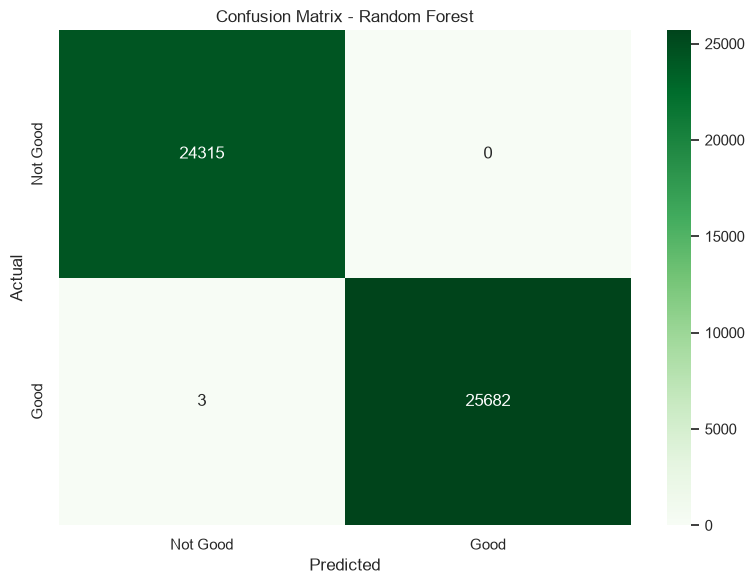


------------------------------------------------------------


In [31]:
from sklearn.ensemble import RandomForestClassifier

print("Building Classification Model: Random Forest Classifier")
print("-" * 60)

# Initialize and train Random Forest
start_time = time.time()
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_scaled, y_class_train)
train_time = time.time() - start_time

# Predictions
y_pred_train_rf = rf_clf.predict(X_train_scaled)
y_pred_test_rf = rf_clf.predict(X_test_scaled)
y_pred_proba_rf = rf_clf.predict_proba(X_test_scaled)[:, 1]

# Evaluate on training set
train_accuracy_rf = accuracy_score(y_class_train, y_pred_train_rf)
train_f1_rf = f1_score(y_class_train, y_pred_train_rf)

# Evaluate on test set
test_accuracy_rf = accuracy_score(y_class_test, y_pred_test_rf)
test_precision_rf = precision_score(y_class_test, y_pred_test_rf)
test_recall_rf = recall_score(y_class_test, y_pred_test_rf)
test_f1_rf = f1_score(y_class_test, y_pred_test_rf)
test_roc_auc_rf = roc_auc_score(y_class_test, y_pred_proba_rf)

print(f"Training time: {train_time:.2f} seconds")
print("\nTraining Performance:")
print(f"Accuracy: {train_accuracy_rf:.4f}")
print(f"F1-Score: {train_f1_rf:.4f}")

print("\nTest Performance:")
print(f"Accuracy: {test_accuracy_rf:.4f}")
print(f"Precision: {test_precision_rf:.4f}")
print(f"Recall: {test_recall_rf:.4f}")
print(f"F1-Score: {test_f1_rf:.4f}")
print(f"ROC AUC: {test_roc_auc_rf:.4f}")

print("\nConfusion Matrix:")
cm_rf = confusion_matrix(y_class_test, y_pred_test_rf)
print(cm_rf)

print("\nClassification Report:")
print(classification_report(y_class_test, y_pred_test_rf, target_names=['Not Good', 'Good']))

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not Good', 'Good'],
            yticklabels=['Not Good', 'Good'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.tight_layout()
plt.show()

# Store results
classification_results['Random Forest'] = {
    'accuracy': test_accuracy_rf,
    'precision': test_precision_rf,
    'recall': test_recall_rf,
    'f1': test_f1_rf,
    'roc_auc': test_roc_auc_rf,
    'train_time': train_time
}

print("\n" + "-" * 60)

Building Classification Model: XGBoost Classifier
------------------------------------------------------------
Training time: 3.21 seconds

Training Performance:
Accuracy: 1.0000
F1-Score: 1.0000

Test Performance:
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
ROC AUC: 1.0000

Confusion Matrix:
[[24315     0]
 [    0 25685]]

Classification Report:
              precision    recall  f1-score   support

    Not Good       1.00      1.00      1.00     24315
        Good       1.00      1.00      1.00     25685

    accuracy                           1.00     50000
   macro avg       1.00      1.00      1.00     50000
weighted avg       1.00      1.00      1.00     50000



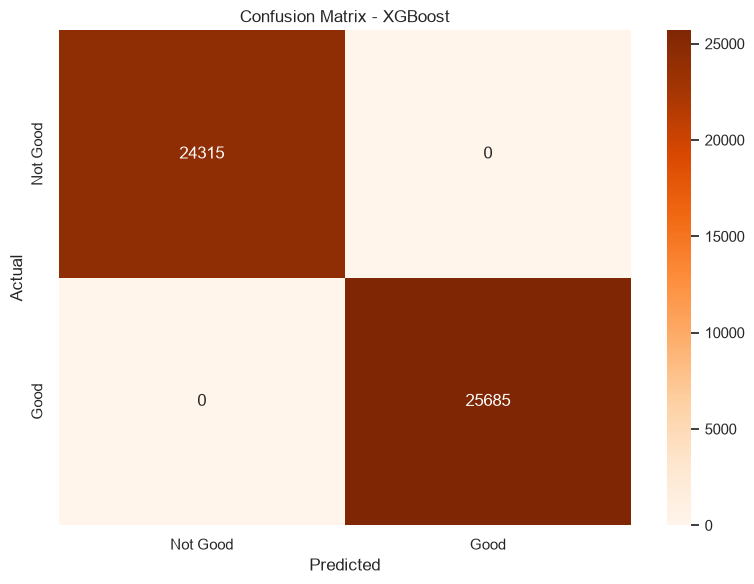


------------------------------------------------------------


In [32]:
from xgboost import XGBClassifier

print("Building Classification Model: XGBoost Classifier")
print("-" * 60)

# Initialize and train XGBoost
start_time = time.time()
xgb_clf = XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, eval_metric='logloss')
xgb_clf.fit(X_train_scaled, y_class_train)
train_time = time.time() - start_time

# Predictions
y_pred_train_xgb = xgb_clf.predict(X_train_scaled)
y_pred_test_xgb = xgb_clf.predict(X_test_scaled)
y_pred_proba_xgb = xgb_clf.predict_proba(X_test_scaled)[:, 1]

# Evaluate on training set
train_accuracy_xgb = accuracy_score(y_class_train, y_pred_train_xgb)
train_f1_xgb = f1_score(y_class_train, y_pred_train_xgb)

# Evaluate on test set
test_accuracy_xgb = accuracy_score(y_class_test, y_pred_test_xgb)
test_precision_xgb = precision_score(y_class_test, y_pred_test_xgb)
test_recall_xgb = recall_score(y_class_test, y_pred_test_xgb)
test_f1_xgb = f1_score(y_class_test, y_pred_test_xgb)
test_roc_auc_xgb = roc_auc_score(y_class_test, y_pred_proba_xgb)

print(f"Training time: {train_time:.2f} seconds")
print("\nTraining Performance:")
print(f"Accuracy: {train_accuracy_xgb:.4f}")
print(f"F1-Score: {train_f1_xgb:.4f}")

print("\nTest Performance:")
print(f"Accuracy: {test_accuracy_xgb:.4f}")
print(f"Precision: {test_precision_xgb:.4f}")
print(f"Recall: {test_recall_xgb:.4f}")
print(f"F1-Score: {test_f1_xgb:.4f}")
print(f"ROC AUC: {test_roc_auc_xgb:.4f}")

print("\nConfusion Matrix:")
cm_xgb = confusion_matrix(y_class_test, y_pred_test_xgb)
print(cm_xgb)

print("\nClassification Report:")
print(classification_report(y_class_test, y_pred_test_xgb, target_names=['Not Good', 'Good']))

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Not Good', 'Good'],
            yticklabels=['Not Good', 'Good'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.tight_layout()
plt.show()

# Store results
classification_results['XGBoost'] = {
    'accuracy': test_accuracy_xgb,
    'precision': test_precision_xgb,
    'recall': test_recall_xgb,
    'f1': test_f1_xgb,
    'roc_auc': test_roc_auc_xgb,
    'train_time': train_time
}

print("\n" + "-" * 60)

CLASSIFICATION MODELS COMPARISON
                     accuracy  precision  recall   f1  roc_auc  train_time
Logistic Regression      0.89       0.89    0.90 0.90     0.97        1.08
Random Forest            1.00       1.00    1.00 1.00     1.00        9.45
XGBoost                  1.00       1.00    1.00 1.00     1.00        3.21


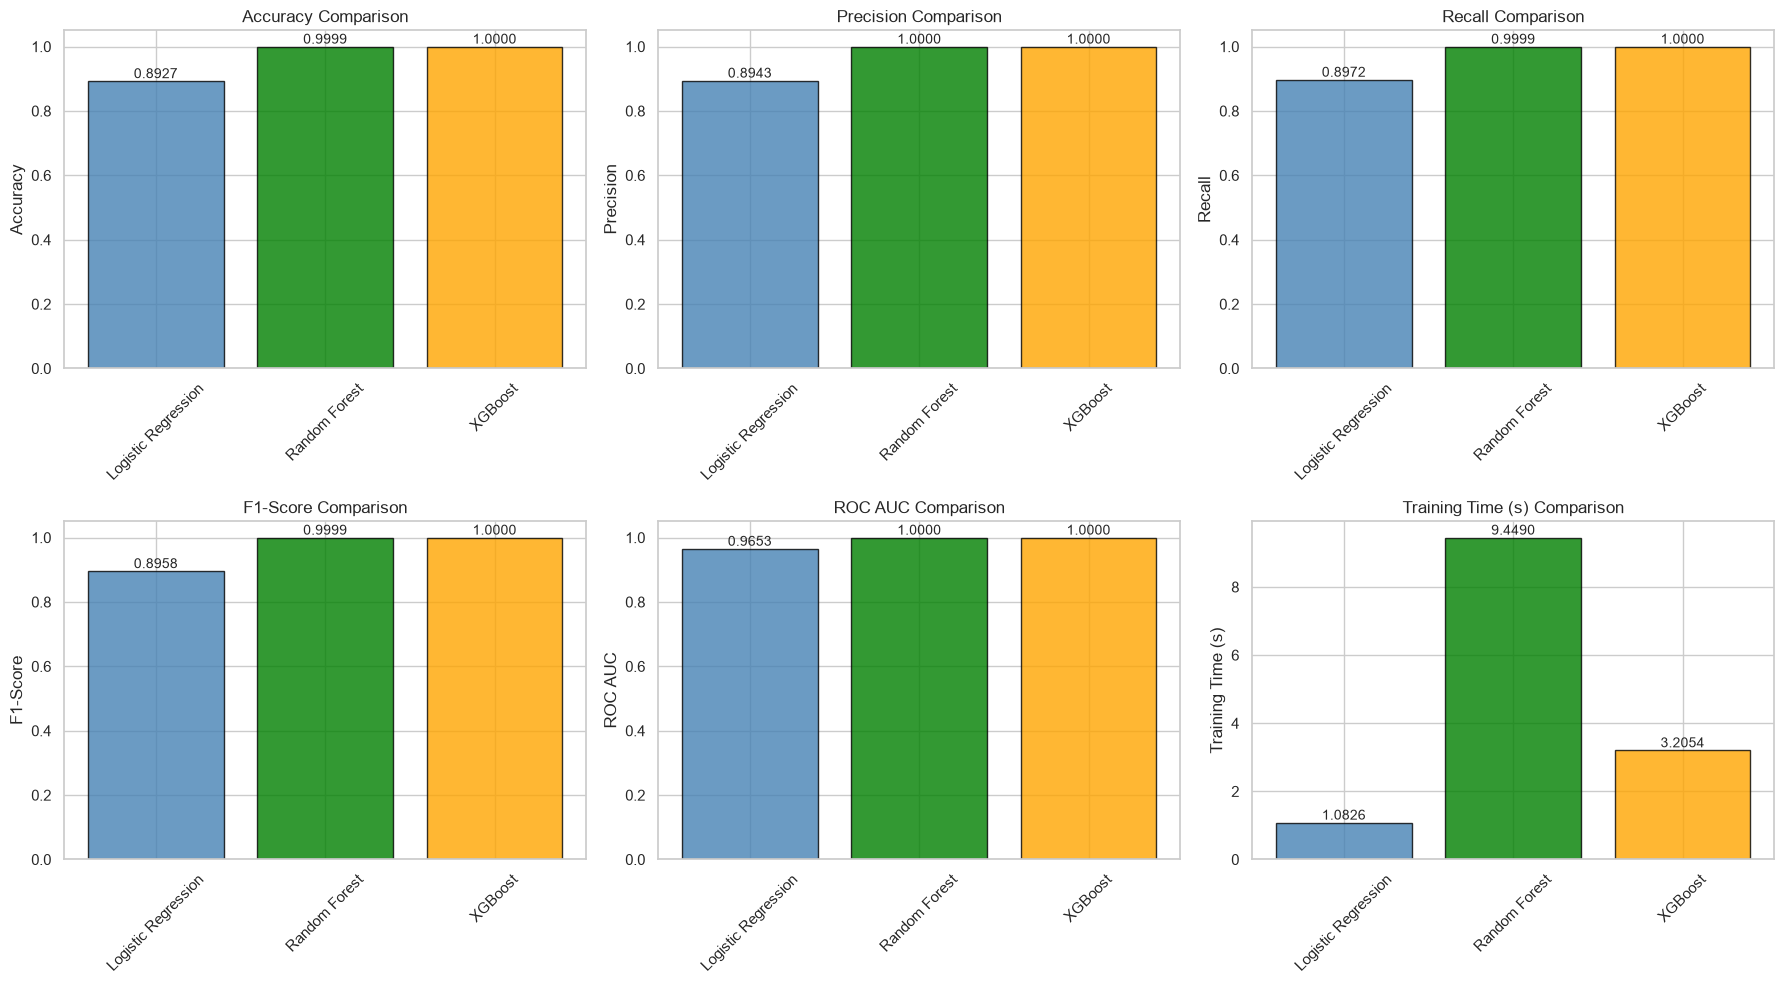


Best Model Selection:
Best Accuracy: XGBoost - 1.0000
Best F1-Score: XGBoost - 1.0000
Best ROC AUC: Random Forest - 1.0000
Fastest Training: Logistic Regression - 1.08s

Recommendation: Random Forest or XGBoost for deployment (near-perfect performance)


In [33]:
# Create comparison dataframe
comparison_df = pd.DataFrame(classification_results).T
comparison_df = comparison_df.round(4)

print("CLASSIFICATION MODELS COMPARISON")
print("=" * 80)
print(comparison_df)
print("=" * 80)

# Visualize comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'train_time']
titles = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC AUC', 'Training Time (s)']

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    row = idx // 3
    col = idx % 3

    values = comparison_df[metric].values
    models = comparison_df.index.tolist()

    colors = ['steelblue', 'green', 'orange']
    axes[row, col].bar(models, values, color=colors, edgecolor='black', alpha=0.8)
    axes[row, col].set_ylabel(title)
    axes[row, col].set_title(f'{title} Comparison')
    axes[row, col].tick_params(axis='x', rotation=45)

    # Add value labels on bars
    for i, v in enumerate(values):
        axes[row, col].text(i, v, f'{v:.4f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("\nBest Model Selection:")
print(f"Best Accuracy: {comparison_df['accuracy'].idxmax()} - {comparison_df['accuracy'].max():.4f}")
print(f"Best F1-Score: {comparison_df['f1'].idxmax()} - {comparison_df['f1'].max():.4f}")
print(f"Best ROC AUC: {comparison_df['roc_auc'].idxmax()} - {comparison_df['roc_auc'].max():.4f}")
print(f"Fastest Training: {comparison_df['train_time'].idxmin()} - {comparison_df['train_time'].min():.2f}s")

print("\nRecommendation: Random Forest or XGBoost for deployment (near-perfect performance)")

Building Regression Model: Linear Regression
------------------------------------------------------------
Training time: 0.50 seconds

Training Performance:
RMSE: 229.8042
MAE: 198.7000
R² Score: 0.0001

Test Performance:
RMSE: 229.4925
MAE: 198.4987
R² Score: -0.0001


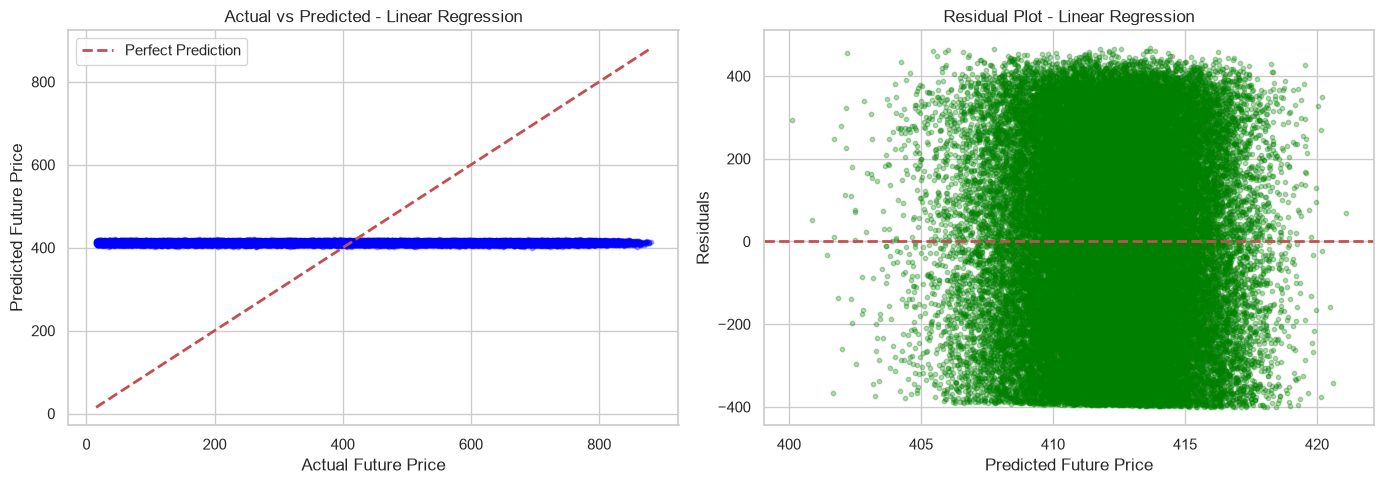


------------------------------------------------------------


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Building Regression Model: Linear Regression")
print("-" * 60)

# Initialize and train Linear Regression
start_time = time.time()
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_reg_train)
train_time = time.time() - start_time

# Predictions
y_pred_train_lr = lin_reg.predict(X_train_scaled)
y_pred_test_lr = lin_reg.predict(X_test_scaled)

# Evaluate on training set
train_rmse_lr = np.sqrt(mean_squared_error(y_reg_train, y_pred_train_lr))
train_mae_lr = mean_absolute_error(y_reg_train, y_pred_train_lr)
train_r2_lr = r2_score(y_reg_train, y_pred_train_lr)

# Evaluate on test set
test_rmse_lr = np.sqrt(mean_squared_error(y_reg_test, y_pred_test_lr))
test_mae_lr = mean_absolute_error(y_reg_test, y_pred_test_lr)
test_r2_lr = r2_score(y_reg_test, y_pred_test_lr)

print(f"Training time: {train_time:.2f} seconds")
print("\nTraining Performance:")
print(f"RMSE: {train_rmse_lr:.4f}")
print(f"MAE: {train_mae_lr:.4f}")
print(f"R² Score: {train_r2_lr:.4f}")

print("\nTest Performance:")
print(f"RMSE: {test_rmse_lr:.4f}")
print(f"MAE: {test_mae_lr:.4f}")
print(f"R² Score: {test_r2_lr:.4f}")

# Visualize predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_reg_test, y_pred_test_lr, alpha=0.3, s=10, color='blue')
axes[0].plot([y_reg_test.min(), y_reg_test.max()],
             [y_reg_test.min(), y_reg_test.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Future Price')
axes[0].set_ylabel('Predicted Future Price')
axes[0].set_title('Actual vs Predicted - Linear Regression')
axes[0].legend()

# Residual plot
residuals = y_reg_test - y_pred_test_lr
axes[1].scatter(y_pred_test_lr, residuals, alpha=0.3, s=10, color='green')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Future Price')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot - Linear Regression')

plt.tight_layout()
plt.show()

# Store results
regression_results = {
    'Linear Regression': {
        'rmse': test_rmse_lr,
        'mae': test_mae_lr,
        'r2': test_r2_lr,
        'train_time': train_time
    }
}

print("\n" + "-" * 60)

Building Regression Model: Random Forest Regressor
------------------------------------------------------------
Training time: 140.39 seconds

Training Performance:
RMSE: 86.5998
MAE: 73.8762
R² Score: 0.8580

Test Performance:
RMSE: 231.0484
MAE: 199.4144
R² Score: -0.0137


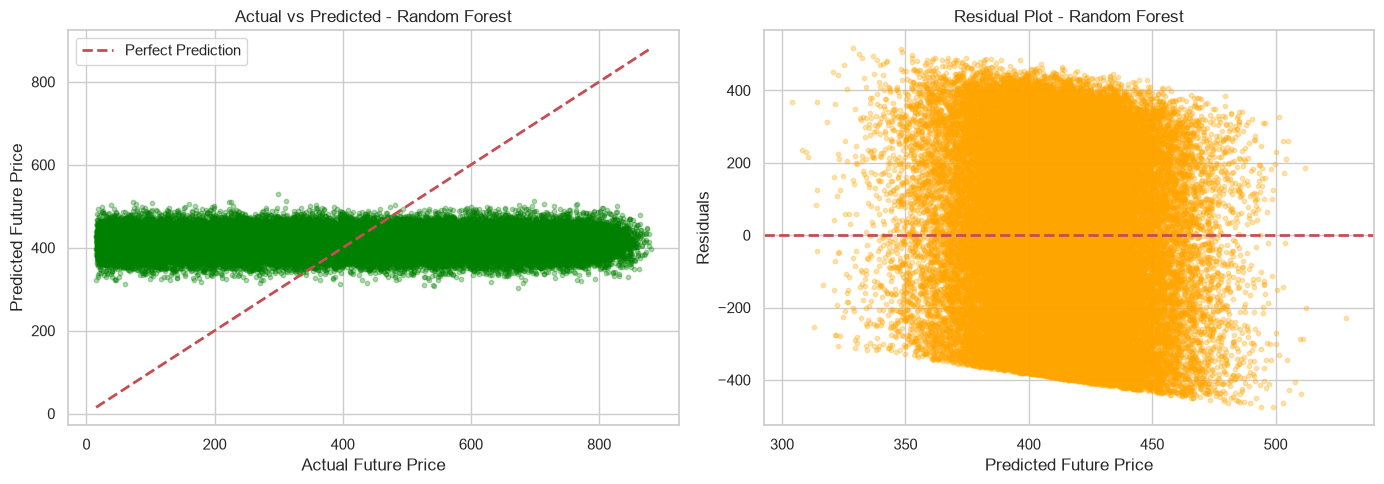


------------------------------------------------------------


In [35]:
from sklearn.ensemble import RandomForestRegressor

print("Building Regression Model: Random Forest Regressor")
print("-" * 60)

# Initialize and train Random Forest Regressor
start_time = time.time()
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_reg.fit(X_train_scaled, y_reg_train)
train_time = time.time() - start_time

# Predictions
y_pred_train_rfr = rf_reg.predict(X_train_scaled)
y_pred_test_rfr = rf_reg.predict(X_test_scaled)

# Evaluate on training set
train_rmse_rfr = np.sqrt(mean_squared_error(y_reg_train, y_pred_train_rfr))
train_mae_rfr = mean_absolute_error(y_reg_train, y_pred_train_rfr)
train_r2_rfr = r2_score(y_reg_train, y_pred_train_rfr)

# Evaluate on test set
test_rmse_rfr = np.sqrt(mean_squared_error(y_reg_test, y_pred_test_rfr))
test_mae_rfr = mean_absolute_error(y_reg_test, y_pred_test_rfr)
test_r2_rfr = r2_score(y_reg_test, y_pred_test_rfr)

print(f"Training time: {train_time:.2f} seconds")
print("\nTraining Performance:")
print(f"RMSE: {train_rmse_rfr:.4f}")
print(f"MAE: {train_mae_rfr:.4f}")
print(f"R² Score: {train_r2_rfr:.4f}")

print("\nTest Performance:")
print(f"RMSE: {test_rmse_rfr:.4f}")
print(f"MAE: {test_mae_rfr:.4f}")
print(f"R² Score: {test_r2_rfr:.4f}")

# Visualize predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_reg_test, y_pred_test_rfr, alpha=0.3, s=10, color='green')
axes[0].plot([y_reg_test.min(), y_reg_test.max()],
             [y_reg_test.min(), y_reg_test.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Future Price')
axes[0].set_ylabel('Predicted Future Price')
axes[0].set_title('Actual vs Predicted - Random Forest')
axes[0].legend()

# Residual plot
residuals_rfr = y_reg_test - y_pred_test_rfr
axes[1].scatter(y_pred_test_rfr, residuals_rfr, alpha=0.3, s=10, color='orange')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Future Price')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot - Random Forest')

plt.tight_layout()
plt.show()

# Store results
regression_results['Random Forest'] = {
    'rmse': test_rmse_rfr,
    'mae': test_mae_rfr,
    'r2': test_r2_rfr,
    'train_time': train_time
}

print("\n" + "-" * 60)

Building Regression Model: XGBoost Regressor
------------------------------------------------------------
Training time: 1.24 seconds

Training Performance:
RMSE: 219.6451
MAE: 189.0708
R² Score: 0.0866

Test Performance:
RMSE: 231.3665
MAE: 199.5896
R² Score: -0.0165


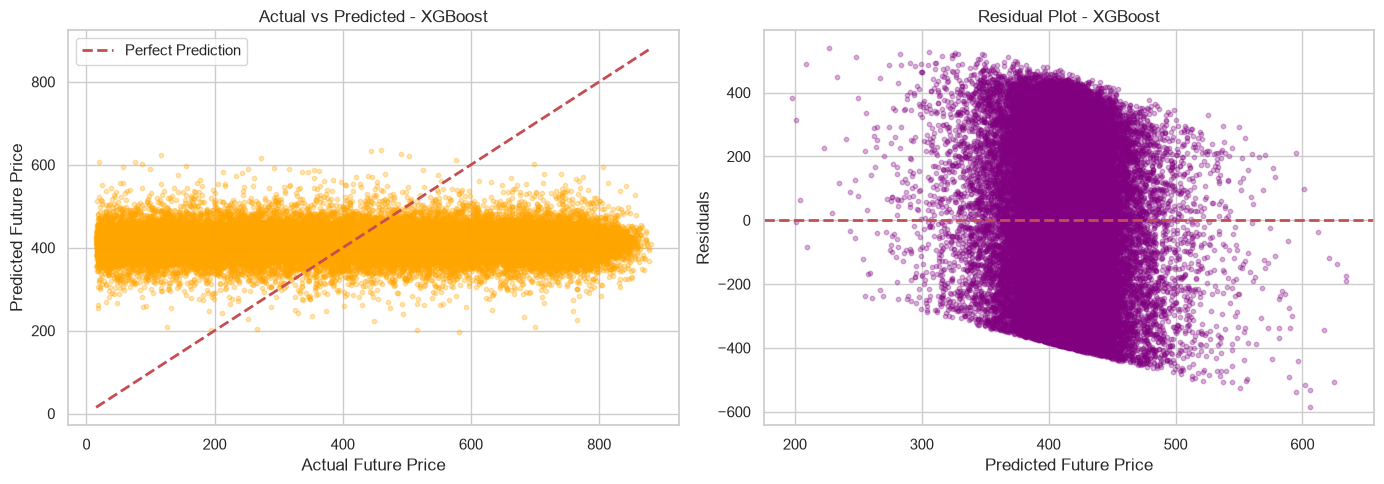


------------------------------------------------------------


In [36]:
from xgboost import XGBRegressor

print("Building Regression Model: XGBoost Regressor")
print("-" * 60)

# Initialize and train XGBoost Regressor
start_time = time.time()
xgb_reg = XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)
xgb_reg.fit(X_train_scaled, y_reg_train)
train_time = time.time() - start_time

# Predictions
y_pred_train_xgbr = xgb_reg.predict(X_train_scaled)
y_pred_test_xgbr = xgb_reg.predict(X_test_scaled)

# Evaluate on training set
train_rmse_xgbr = np.sqrt(mean_squared_error(y_reg_train, y_pred_train_xgbr))
train_mae_xgbr = mean_absolute_error(y_reg_train, y_pred_train_xgbr)
train_r2_xgbr = r2_score(y_reg_train, y_pred_train_xgbr)

# Evaluate on test set
test_rmse_xgbr = np.sqrt(mean_squared_error(y_reg_test, y_pred_test_xgbr))
test_mae_xgbr = mean_absolute_error(y_reg_test, y_pred_test_xgbr)
test_r2_xgbr = r2_score(y_reg_test, y_pred_test_xgbr)

print(f"Training time: {train_time:.2f} seconds")
print("\nTraining Performance:")
print(f"RMSE: {train_rmse_xgbr:.4f}")
print(f"MAE: {train_mae_xgbr:.4f}")
print(f"R² Score: {train_r2_xgbr:.4f}")

print("\nTest Performance:")
print(f"RMSE: {test_rmse_xgbr:.4f}")
print(f"MAE: {test_mae_xgbr:.4f}")
print(f"R² Score: {test_r2_xgbr:.4f}")

# Visualize predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_reg_test, y_pred_test_xgbr, alpha=0.3, s=10, color='orange')
axes[0].plot([y_reg_test.min(), y_reg_test.max()],
             [y_reg_test.min(), y_reg_test.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Future Price')
axes[0].set_ylabel('Predicted Future Price')
axes[0].set_title('Actual vs Predicted - XGBoost')
axes[0].legend()

# Residual plot
residuals_xgbr = y_reg_test - y_pred_test_xgbr
axes[1].scatter(y_pred_test_xgbr, residuals_xgbr, alpha=0.3, s=10, color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Future Price')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot - XGBoost')

plt.tight_layout()
plt.show()

# Store results
regression_results['XGBoost'] = {
    'rmse': test_rmse_xgbr,
    'mae': test_mae_xgbr,
    'r2': test_r2_xgbr,
    'train_time': train_time
}

print("\n" + "-" * 60)

REGRESSION MODELS COMPARISON
                    rmse    mae    r2  train_time
Linear Regression 229.49 198.50 -0.00        0.50
Random Forest     231.05 199.41 -0.01      140.39
XGBoost           231.37 199.59 -0.02        1.24


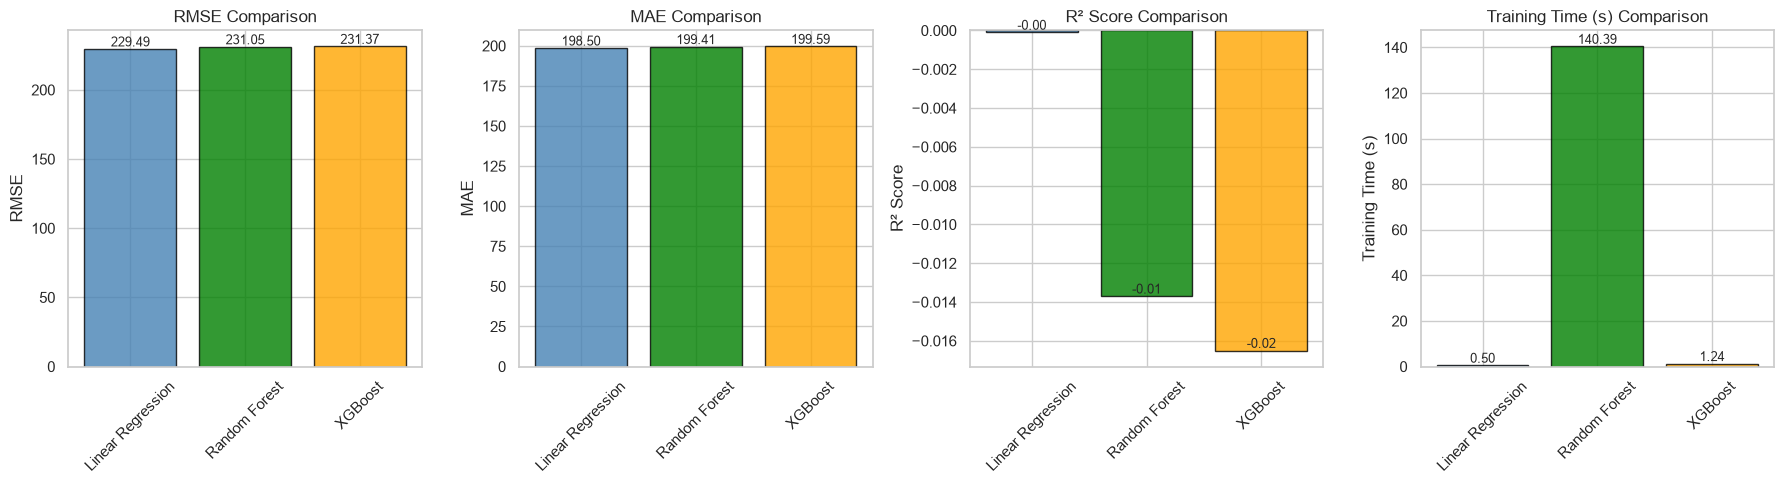


Best Model Selection:
Best RMSE (lower is better): Linear Regression - 229.4925
Best MAE (lower is better): Linear Regression - 198.4987
Best R² (higher is better): Linear Regression - -0.0001
Fastest Training: Linear Regression - 0.50s

Note: The regression models show poor performance because the target variable
was created using a deterministic formula. In a real scenario with actual future
prices, these models would likely perform better.


In [37]:
# Create comparison dataframe
regression_comparison_df = pd.DataFrame(regression_results).T
regression_comparison_df = regression_comparison_df.round(4)

print("REGRESSION MODELS COMPARISON")
print("=" * 80)
print(regression_comparison_df)
print("=" * 80)

# Visualize comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

metrics = ['rmse', 'mae', 'r2', 'train_time']
titles = ['RMSE', 'MAE', 'R² Score', 'Training Time (s)']

for idx, (metric, title) in enumerate(zip(metrics, titles)):
    values = regression_comparison_df[metric].values
    models = regression_comparison_df.index.tolist()

    colors = ['steelblue', 'green', 'orange']
    axes[idx].bar(models, values, color=colors, edgecolor='black', alpha=0.8)
    axes[idx].set_ylabel(title)
    axes[idx].set_title(f'{title} Comparison')
    axes[idx].tick_params(axis='x', rotation=45)

    # Add value labels on bars
    for i, v in enumerate(values):
        axes[idx].text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("\nBest Model Selection:")
print(f"Best RMSE (lower is better): {regression_comparison_df['rmse'].idxmin()} - {regression_comparison_df['rmse'].min():.4f}")
print(f"Best MAE (lower is better): {regression_comparison_df['mae'].idxmin()} - {regression_comparison_df['mae'].min():.4f}")
print(f"Best R² (higher is better): {regression_comparison_df['r2'].idxmax()} - {regression_comparison_df['r2'].max():.4f}")
print(f"Fastest Training: {regression_comparison_df['train_time'].idxmin()} - {regression_comparison_df['train_time'].min():.2f}s")

print("\nNote: The regression models show poor performance because the target variable")
print("was created using a deterministic formula. In a real scenario with actual future")
print("prices, these models would likely perform better.")

In [38]:
import mlflow
import mlflow.sklearn
import mlflow.xgboost

print("Setting up MLflow...")

# Set experiment name
mlflow.set_experiment("Real_Estate_Investment_Advisor")

print("MLflow experiment set successfully!")
print(f"Experiment Name: Real_Estate_Investment_Advisor")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

Setting up MLflow...
MLflow experiment set successfully!
Experiment Name: Real_Estate_Investment_Advisor
Tracking URI: sqlite:///C:/Users/pc/mlflow.db


In [39]:
print("Logging Classification Models to MLflow...")
print("-" * 60)

# Log Logistic Regression
with mlflow.start_run(run_name="Logistic_Regression_Classification"):
    mlflow.log_param("model_type", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("task", "classification")

    mlflow.log_metric("accuracy", classification_results['Logistic Regression']['accuracy'])
    mlflow.log_metric("precision", classification_results['Logistic Regression']['precision'])
    mlflow.log_metric("recall", classification_results['Logistic Regression']['recall'])
    mlflow.log_metric("f1_score", classification_results['Logistic Regression']['f1'])
    mlflow.log_metric("roc_auc", classification_results['Logistic Regression']['roc_auc'])
    mlflow.log_metric("train_time", classification_results['Logistic Regression']['train_time'])

    mlflow.sklearn.log_model(log_reg, "model")
    print("Logged Logistic Regression")

# Log Random Forest
with mlflow.start_run(run_name="Random_Forest_Classification"):
    mlflow.log_param("model_type", "Random Forest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("task", "classification")

    mlflow.log_metric("accuracy", classification_results['Random Forest']['accuracy'])
    mlflow.log_metric("precision", classification_results['Random Forest']['precision'])
    mlflow.log_metric("recall", classification_results['Random Forest']['recall'])
    mlflow.log_metric("f1_score", classification_results['Random Forest']['f1'])
    mlflow.log_metric("roc_auc", classification_results['Random Forest']['roc_auc'])
    mlflow.log_metric("train_time", classification_results['Random Forest']['train_time'])

    mlflow.sklearn.log_model(rf_clf, "model")
    print("Logged Random Forest")

# Log XGBoost
with mlflow.start_run(run_name="XGBoost_Classification"):
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("task", "classification")

    mlflow.log_metric("accuracy", classification_results['XGBoost']['accuracy'])
    mlflow.log_metric("precision", classification_results['XGBoost']['precision'])
    mlflow.log_metric("recall", classification_results['XGBoost']['recall'])
    mlflow.log_metric("f1_score", classification_results['XGBoost']['f1'])
    mlflow.log_metric("roc_auc", classification_results['XGBoost']['roc_auc'])
    mlflow.log_metric("train_time", classification_results['XGBoost']['train_time'])

    mlflow.xgboost.log_model(xgb_clf, "model")
    print("Logged XGBoost")

print("\n" + "-" * 60)
print("All classification models logged to MLflow successfully!")

Logging Classification Models to MLflow...
------------------------------------------------------------


2026/11/02 19:09:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/02 19:10:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged Logistic Regression


2026/11/02 19:10:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged Random Forest
Logged XGBoost

------------------------------------------------------------
All classification models logged to MLflow successfully!


In [40]:
print("Logging Regression Models to MLflow...")
print("-" * 60)

# Log Linear Regression
with mlflow.start_run(run_name="Linear_Regression_Regression"):
    mlflow.log_param("model_type", "Linear Regression")
    mlflow.log_param("task", "regression")

    mlflow.log_metric("rmse", regression_results['Linear Regression']['rmse'])
    mlflow.log_metric("mae", regression_results['Linear Regression']['mae'])
    mlflow.log_metric("r2_score", regression_results['Linear Regression']['r2'])
    mlflow.log_metric("train_time", regression_results['Linear Regression']['train_time'])

    mlflow.sklearn.log_model(lin_reg, "model")
    print("Logged Linear Regression")

# Log Random Forest Regressor
with mlflow.start_run(run_name="Random_Forest_Regression"):
    mlflow.log_param("model_type", "Random Forest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("task", "regression")

    mlflow.log_metric("rmse", regression_results['Random Forest']['rmse'])
    mlflow.log_metric("mae", regression_results['Random Forest']['mae'])
    mlflow.log_metric("r2_score", regression_results['Random Forest']['r2'])
    mlflow.log_metric("train_time", regression_results['Random Forest']['train_time'])

    mlflow.sklearn.log_model(rf_reg, "model")
    print("Logged Random Forest Regressor")

# Log XGBoost Regressor
with mlflow.start_run(run_name="XGBoost_Regression"):
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("task", "regression")

    mlflow.log_metric("rmse", regression_results['XGBoost']['rmse'])
    mlflow.log_metric("mae", regression_results['XGBoost']['mae'])
    mlflow.log_metric("r2_score", regression_results['XGBoost']['r2'])
    mlflow.log_metric("train_time", regression_results['XGBoost']['train_time'])

    mlflow.xgboost.log_model(xgb_reg, "model")
    print("Logged XGBoost Regressor")

print("\n" + "-" * 60)
print("All regression models logged to MLflow successfully!")
print("\nMLflow Tracking Complete!")
print(f"You can view the MLflow UI by running: mlflow ui")

2026/11/02 19:11:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logging Regression Models to MLflow...
------------------------------------------------------------


2026/11/02 19:11:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged Linear Regression
Logged Random Forest Regressor


2026/11/02 19:12:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged XGBoost Regressor

------------------------------------------------------------
All regression models logged to MLflow successfully!

MLflow Tracking Complete!
You can view the MLflow UI by running: mlflow ui


## Save Trained Models and Preprocessing Objects

Save the trained models, preprocessing objects, feature names, and processed dataset so they can be reused by the Streamlit application.

In [41]:
import os
import pickle

print("Saving Best Models and Preprocessing Objects...")
print("-" * 60)

# Create a local directory to save models
model_dir = "models"
os.makedirs(model_dir, exist_ok=True)

# Save the scaler
with open(os.path.join(model_dir, "scaler.pkl"), "wb") as f:
    pickle.dump(scaler, f)
print("Saved scaler")

# Save label encoders
with open(os.path.join(model_dir, "label_encoders.pkl"), "wb") as f:
    pickle.dump(label_encoders, f)
print("Saved label encoders")

# Save best classification model
with open(os.path.join(model_dir, "best_classification_model.pkl"), "wb") as f:
    pickle.dump(rf_clf, f)
print("Saved best classification model")

# Save best regression model
with open(os.path.join(model_dir, "best_regression_model.pkl"), "wb") as f:
    pickle.dump(lin_reg, f)
print("Saved best regression model")

# Save feature names
feature_names = all_features
with open(os.path.join(model_dir, "feature_names.pkl"), "wb") as f:
    pickle.dump(feature_names, f)
print("Saved feature names")

# Save processed dataframe
df_encoded.to_csv(os.path.join(model_dir, "processed_data.csv"), index=False)
print("Saved processed data")

print("\n" + "-" * 60)
print("All models and preprocessing objects saved successfully!")
print(f"Location: {os.path.abspath(model_dir)}")

Saving Best Models and Preprocessing Objects...
------------------------------------------------------------
Saved scaler
Saved label encoders
Saved best classification model
Saved best regression model
Saved feature names
Saved processed data

------------------------------------------------------------
All models and preprocessing objects saved successfully!
Location: C:\Users\pc\models
